# TUAB data preparation for LaBraM — from raw EDF to model input

📄 **[PDF version of this notebook](tuab_data_preparation.pdf)** (figures, tables and formulas, no code;
regenerate with section 13).

This notebook walks through, step by step and on **real recordings**, how the
Temple University Hospital **Abnormal EEG Corpus (TUAB v3.0.0)** is turned into the
tensors LaBraM is fine-tuned on. Every step is (1) explained, (2) written as a
numbered formula, and (3) visualised on a **normal** and an **abnormal** recording.

The code that does this in the repo is
[`dataset_maker/make_TUAB.py`](../dataset_maker/make_TUAB.py) (offline, EDF → pickle)
plus a few lines at training time in
[`labram/train/train_finetune.py`](../labram/train/train_finetune.py) (pickle → model input).
The notebook **re-implements the pipeline with the same MNE calls and the same constants
(imported from `make_TUAB.py`)** and checks in section 7 (Table 7.1) that it reproduces the
stored pickles exactly. Table 0.1 lists the steps.

**Numbering.** Equations, tables and figures are numbered per section (`Eq. (4.3)`,
`Table 2.2`, `Figure 4.2(b)`); every table and figure sits under its own `Table s.k.` /
`Figure s.k.` heading, and every panel carries a letter.

### Table 0.1. The pipeline at a glance

Shapes are `[channels, samples]`; $T$ is the recording length in seconds.

| # | Step | Where | Shape after the step | Section |
|---|------|-------|-----------------------|---|
| 0 | Read EDF, convert to µV | `mne.io.read_raw_edf` | `[C_raw ≈ 30–36, 250·T]` @ 250 Hz | 2 |
| 1 | Drop non-EEG channels, reorder to 23 standard channels | `raw.drop_channels`, `raw.reorder_channels` | `[23, 250·T]` | 3 |
| 2 | Band-pass FIR 0.1–75 Hz (zero phase) | `raw.filter(0.1, 75)` | `[23, 250·T]` | 4 |
| 3 | Notch FIR at 50 Hz | `raw.notch_filter(50)` | `[23, 250·T]` | 5 |
| 4 | Resample 250 → 200 Hz (FFT) | `raw.resample(200)` | `[23, 200·T]` | 6 |
| 5 | Cut into non-overlapping 10 s windows, label = folder | `X[:, 2000k : 2000(k+1)]` | `K × [23, 2000]` | 7 |
| 6 | *(training time)* scale ÷100, split into 1 s patches | `train_finetune.py` | `[23, 10, 200]` | 8 |
| 7 | *(optional, LaBraM++)* common average reference + per-patch z-score | `labram/data/preprocess.py` | `[23, 10, 200]` | 9 |

### Contents
1. The TUAB corpus: layout, labels, splits
2. Raw EDF signals, and the grand-average spectrum of the cohort (50 / 60 / 75 Hz peaks)
3. Step 1 — channel selection & ordering
4. Step 2 — band-pass filter 0.1–75 Hz (30 s before/after views)
5. Step 3 — 50 Hz notch filter (and why 60 Hz survives)
6. Step 4 — resampling 250 → 200 Hz
7. Step 5 — windowing into 10 s samples, labels, verification against stored pickles
8. Step 6 — what the model actually receives (÷100, patches, channel indices)
9. Step 7 — optional LaBraM++ preprocessing (CAR + z-score)
10. Normal vs abnormal: gallery of examples & class-level spectra
11. Summary of formulas & caveats
12. Comparison with other state-of-the-art preprocessing pipelines (foundation models & brain-age models)
13. Export to PDF

> **Requirements:** `mne`, `numpy`, `scipy`, `pandas`, `matplotlib`, `torch` (all in `requirements.txt`).
> Point `TUAB_ROOT` (below, or the `TUAB_ROOT` environment variable) to the `v3.0.0/edf`
> directory. The `processed/` sub-folder produced by `make_TUAB.py` is needed for sections 2.1, 7, 10
> and 11; those parts are skipped if it is missing.

## Setup

In [1]:
import os
import sys
import pickle
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.signal as ss
import matplotlib.pyplot as plt
import mne
from IPython.display import display

# --- paths -----------------------------------------------------------------
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / "dataset_maker"))

TUAB_ROOT = Path(os.environ.get(
    "TUAB_ROOT", "/data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf"))
MONTAGE = "01_tcp_ar"                       # same as `channel_std` in make_TUAB.py
PROCESSED = TUAB_ROOT / "processed"         # output of make_TUAB.py (train/val/test)
assert TUAB_ROOT.exists(), f"TUAB_ROOT not found: {TUAB_ROOT}"

# --- the exact constants used by the preprocessing script --------------------
from make_TUAB import drop_channels, chOrder_standard   # noqa: E402
# --- house-style numbering helpers (Figure s.k titles, (a)/(b) panels, tables) --
from labram.eval.age_plots import assert_max_columns, figure_heading, numbered_table, panel_labels  # noqa: E402

L_FREQ, H_FREQ = 0.1, 75.0     # raw.filter(l_freq=0.1, h_freq=75.0)
NOTCH_FREQ = 50.0              # raw.notch_filter(50.0)
TARGET_SFREQ = 200             # raw.resample(200)
WINDOW = 2000                  # 2000 samples = 10 s at 200 Hz
PATCH = 200                    # 1 s patches at training time

mne.set_log_level("ERROR")

# --- plotting style: one colour per class, used everywhere ---------------------
C_NORMAL, C_ABNORMAL = "#2a78d6", "#eb6834"
C_BEFORE, C_AFTER = "#9b9a95", "#2a78d6"
CLASS_COLOR = {0: C_NORMAL, 1: C_ABNORMAL}
CLASS_NAME = {0: "normal", 1: "abnormal"}
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False,
})
print("MNE", mne.__version__, "| TUAB root:", TUAB_ROOT)

MNE 1.4.2 | TUAB root: /data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf


In [2]:
# ---------------------------------------------------------------------------
# Helpers used throughout the notebook
# ---------------------------------------------------------------------------
def short(ch):
    # 'EEG FP1-REF' -> 'FP1' (same rule as labram.data.eeg_constants.normalize_ch_names)
    return ch.split(" ")[-1].split("-")[0]


def finish(fig, axes=None):
    # House style: lay out, letter the panels (a), (b), ... in reading order,
    # check <= 2 axes per row, show. The figure's number and title are the
    # "Figure s.k." Markdown heading above the cell (no suptitle).
    fig.tight_layout()
    if axes is not None and len(axes) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    plt.show()


def plot_stacked(ax, X, ch_names, sfreq, t0=0.0, dur=10.0, spacing=None, color="k",
                 title=None, lw=0.6, clip=True, unit="µV", labels=None):
    # Stacked multichannel EEG trace. X in µV, shape [C, N].
    # Per-channel mean in the shown window is removed for display only.
    i0, i1 = int(round(t0 * sfreq)), int(round((t0 + dur) * sfreq))
    seg = X[:, i0:i1]
    seg = seg - seg.mean(axis=1, keepdims=True)
    if spacing is None:
        spacing = 4.0 * np.median(np.std(seg, axis=1))
        spacing = float(np.ceil(spacing / 10.0) * 10.0)
    t = t0 + np.arange(seg.shape[1]) / sfreq
    offsets = -np.arange(len(seg)) * spacing
    for y, off in zip(seg, offsets):
        if clip:
            y = np.clip(y, -1.5 * spacing, 1.5 * spacing)
        ax.plot(t, y + off, color=color, lw=lw)
    ax.set_yticks(offsets)
    ax.set_yticklabels(labels if labels is not None else [short(c) for c in ch_names], fontsize=7)
    ax.set_ylim(offsets[-1] - 1.5 * spacing, 1.5 * spacing)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("time [s]")
    ax.grid(False)
    if title:
        ax.set_title(f"{title}   (trace spacing = {spacing:g} {unit})")
    return spacing


def thick_legend(ax, **kw):
    # Legend whose line samples are thicker than the (thin) data lines
    leg = ax.legend(**kw)
    for line in leg.get_lines():
        line.set_linewidth(2.5)
    return leg


def welch_psd(X, sfreq, seg_sec=4.0):
    # Eq. (2.2): Welch PSD per channel, Hann window, 50 % overlap.
    # X [C, N] in µV -> (f [Hz], P [C, F] in µV²/Hz).
    nper = int(seg_sec * sfreq)
    f, P = ss.welch(X, fs=sfreq, nperseg=nper, noverlap=nper // 2, axis=-1)
    return f, P


def line_prominence_db(f, P, f0, half=0.5):
    # Eq. (2.5): peak of the channel-averaged PSD within f0 ± 0.5 Hz relative to the
    # median PSD of the neighbourhood 1 Hz < |f - f0| < 5 Hz, in dB.
    Pm = P.mean(axis=0) if P.ndim == 2 else P
    peak = np.nanmax(Pm[(f >= f0 - half) & (f <= f0 + half)])
    nb = (np.abs(f - f0) > 1.0) & (np.abs(f - f0) < 5.0)
    return 10 * np.log10(peak / np.nanmedian(Pm[nb]))


def line_power_db(f, P, f0, half=0.5, band=(1.0, 45.0)):
    # Eq. (2.6): power in f0 ± 0.5 Hz relative to the power of the 1-45 Hz EEG band, in dB.
    Pm = P.mean(axis=0) if P.ndim == 2 else P
    m_line = (f >= f0 - half) & (f <= f0 + half)
    m_eeg = (f >= band[0]) & (f <= band[1])
    return 10 * np.log10(np.trapz(Pm[m_line], f[m_line]) / np.trapz(Pm[m_eeg], f[m_eeg]))


def edf_path(split, label, stem):
    folder = "abnormal" if label == 1 else "normal"
    return TUAB_ROOT / split / folder / MONTAGE / f"{stem}.edf"


def run_pipeline(path, keep_stages=True):
    # Re-implements make_TUAB.split_and_dump step by step, keeping a copy (in µV) after
    # every step. Returns dict: stage name -> (X [C, N] µV, channel names, sfreq), windows.
    stages = {}

    def snap(name):
        if keep_stages or name in ("0 raw", "4 resampled"):
            stages[name] = (raw.get_data(units="uV"), list(raw.ch_names), raw.info["sfreq"])

    raw = mne.io.read_raw_edf(path, preload=True)
    snap("0 raw")
    # step 1 — channel selection / ordering, Eq. (3.1)
    raw.drop_channels([ch for ch in drop_channels if ch in raw.ch_names])
    if len(chOrder_standard) == len(raw.ch_names):
        raw.reorder_channels(chOrder_standard)
    if raw.ch_names != chOrder_standard:
        raise RuntimeError(f"channel order is wrong for {path.name}: {raw.ch_names}")
    snap("1 channels")
    raw.filter(l_freq=L_FREQ, h_freq=H_FREQ)          # step 2, Eqs. (4.1)-(4.5)
    snap("2 band-pass")
    raw.notch_filter(NOTCH_FREQ)                       # step 3, Eq. (5.1)
    snap("3 notch")
    raw.resample(TARGET_SFREQ)                         # step 4, Eqs. (6.1)-(6.2)
    snap("4 resampled")
    X = stages["4 resampled"][0]                       # step 5, Eq. (7.1)
    windows = np.stack([X[:, i * WINDOW:(i + 1) * WINDOW] for i in range(X.shape[1] // WINDOW)])
    return stages, windows

## 1. The TUAB corpus: layout, labels, splits

TUAB is a subset of the TUH EEG Corpus: routine clinical EEGs, each recording annotated by a
neurologist as **normal** or **abnormal** (based on the clinical report). The label is a
property of the **whole recording** — there is no time-resolved annotation.

```
v3.0.0/edf/
├── train/ ─┬─ normal/01_tcp_ar/aaaaaaav_s004_t000.edf
│           └─ abnormal/01_tcp_ar/...
└── eval/  ─┬─ normal/01_tcp_ar/...
            └─ abnormal/01_tcp_ar/...
```

* File name = `<subject>_<session>_<token>.edf` — e.g. `aaaaaaav_s004_t000` is subject
  `aaaaaaav`, session 4, the first EDF file of that session.
* **Label** comes only from the folder name: $y = 1$ for `abnormal/`, $y = 0$ for `normal/`.
* `01_tcp_ar` = recordings made with an *averaged reference* (AR) electrode configuration;
  every channel is a referential channel named `EEG XX-REF`.

**How `make_TUAB.py` splits the data** (subject-level, done separately for each class $c$):

$$
\begin{aligned}
\mathcal S^{c} &= \operatorname{shuffle}\big(\{\text{subject ids in } \texttt{train}/c\}\big),\\
\mathcal S^{c}_{\text{train}} &= \mathcal S^{c}_{[\,0 : \lfloor 0.8\,|\mathcal S^{c}|\rfloor\,)},\qquad
\mathcal S^{c}_{\text{val}} = \mathcal S^{c}_{[\,\lfloor 0.8\,|\mathcal S^{c}|\rfloor : \,]}
\end{aligned}
\tag{1.1}
$$

where $c \in \{\text{normal}, \text{abnormal}\}$ and $|\mathcal S^{c}|$ is the number of subjects; the
official `eval/` folder becomes the **test** set. Table 1.1 and Figure 1.1 count recordings and
subjects per folder. (Caveats about Eq. (1.1) are in section 11, Table 11.2.)

### Table 1.1. Recordings and subjects per TUAB folder

`#recordings` counts EDF files, `#subjects` distinct subject ids (first token of the file name).

In [3]:
rows = []
for split in ["train", "eval"]:
    for label, folder in [(0, "normal"), (1, "abnormal")]:
        files = sorted(p.name for p in (TUAB_ROOT / split / folder / MONTAGE).glob("*.edf"))
        rows.append(dict(folder=f"{split}/{folder}", y=label, recordings=len(files),
                         subjects=len({f.split("_")[0] for f in files})))
counts = pd.DataFrame(rows).set_index("folder")
display(numbered_table(counts, "1.1", "recordings and subjects per folder", precision=0))

,y,recordings,subjects
folder,,,
train/normal,0,1371,1237
train/abnormal,1,1346,893
eval/normal,0,150,148
eval/abnormal,1,126,105


### Figure 1.1. TUAB v3.0.0 recordings per folder

Number of EDF recordings per TUAB folder and class (all of TUAB v3.0.0;
`train/` is later split into train + val by Eq. (1.1), `eval/` is the test set).

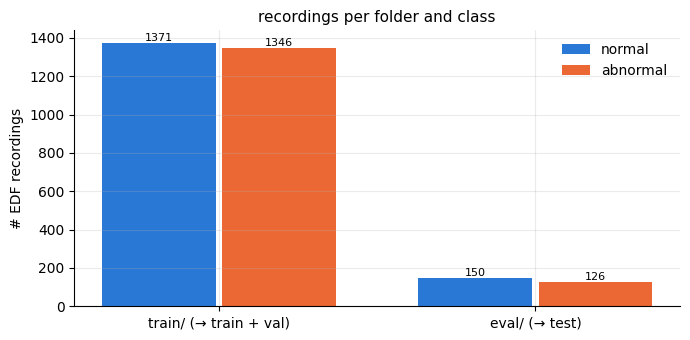

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(2)
for j, (label, name) in enumerate([(0, "normal"), (1, "abnormal")]):
    vals = counts[counts.y == label].recordings.values
    bars = ax.bar(x + (j - 0.5) * 0.38, vals, width=0.36, color=CLASS_COLOR[label], label=name)
    ax.bar_label(bars, fontsize=8)
ax.set_xticks(x, ["train/ (→ train + val)", "eval/ (→ test)"])
ax.set_ylabel("# EDF recordings")
ax.set_title("recordings per folder and class")
ax.legend()
finish(fig)

### Examples used in the walk-through

We use recordings from the `eval/` (= test) folder, taken in sorted order so the choice is
deterministic. Change `EXAMPLE_NORMAL` / `EXAMPLE_ABNORMAL` to look at other recordings.
`SHOW_T0` is the start (in seconds) of the **10 s window that is shown after every processing step**
(Figures 2.1, 3.2, 4.2–4.4, 5.2, 6.2, 7.2, 8.1, 9.1, 11.1). It is a multiple of 10 s, so the excerpt is
exactly one of the stored windows of Eq. (7.1). The first minute of a clinical EEG often contains set-up
artefacts, so we look a bit later.

In [5]:
eval_normal = sorted(p.stem for p in (TUAB_ROOT / "eval/normal" / MONTAGE).glob("*.edf"))
eval_abnormal = sorted(p.stem for p in (TUAB_ROOT / "eval/abnormal" / MONTAGE).glob("*.edf"))

EXAMPLE_NORMAL = eval_normal[0]
EXAMPLE_ABNORMAL = eval_abnormal[0]
SHOW_T0, SHOW_DUR = 120.0, 10.0          # SHOW_T0 is a multiple of 10 s -> this excerpt IS stored window SHOW_T0/10

examples = {0: EXAMPLE_NORMAL, 1: EXAMPLE_ABNORMAL}
pipe = {}
for label, stem in examples.items():
    pipe[label] = run_pipeline(edf_path("eval", label, stem))
    print(f"{CLASS_NAME[label]:9s} {stem}: processed into {len(pipe[label][1])} windows")

normal    aaaaaayx_s002_t000: processed into 120 windows


abnormal  aaaaabdo_s003_t000: processed into 121 windows


## 2. Raw EDF signals

An EDF file stores each channel as 16-bit integers $d[n]$ together with a calibration in the
header. MNE converts them to volts, and `get_data(units="uV")` converts to microvolts:

$$
x[n] = 10^{6}\Big(p_{\min} + \big(d[n] - d_{\min}\big)\,\frac{p_{\max} - p_{\min}}{d_{\max} - d_{\min}}\Big)
\tag{2.1}
$$

where $x[n]$ is the sample in µV, $d[n]$ the stored integer, and $d_{\min}, d_{\max}$ /
$p_{\min}, p_{\max}$ the digital / physical (volt) range of the channel from the EDF header.

What the raw recordings look like (Table 2.1, Figure 2.1):
* sampling rate $f_s = 250$ Hz (anti-aliasing low-pass of the amplifier: 125 Hz),
* 30–36 channels — the 23 scalp/ear EEG electrodes **plus** non-EEG channels (EKG, EMG,
  eye leads `ROC/LOC`, photic stimulator, `IBI/BURSTS/SUPPR` analysis channels, unused
  numbered inputs `EEG 26-REF`, …),
* DC offsets and slow drifts, and power-line interference.

### Table 2.1. Header of the two example recordings

`non-EEG channels` are the channels removed in step 1 (section 3).

In [6]:
rows = []
for label, stem in examples.items():
    X, ch, sf = pipe[label][0]["0 raw"]
    rows.append({"class": CLASS_NAME[label], "recording": stem, "sfreq [Hz]": sf,
                 "duration [s]": X.shape[1] / sf, "#channels": len(ch),
                 "non-EEG channels": ", ".join(short(c) for c in ch if c not in chOrder_standard)})
display(numbered_table(pd.DataFrame(rows).set_index("class"), "2.1", "example headers", precision=0))

,recording,sfreq [Hz],duration [s],#channels,non-EEG channels
class,,,,,
normal,aaaaaayx_s002_t000,250,1202,36,"ROC, LOC, EKG1, EMG, 26, 27, 28, 29, 30, PHOTIC, IBI, BURSTS, SUPPR"
abnormal,aaaaabdo_s003_t000,250,1217,30,"ROC, LOC, EKG1, PHOTIC, IBI, BURSTS, SUPPR"


### Figure 2.1. Raw EDF, all channels (step 0)

Raw EDF, all channels, of (a) the normal and (b) the abnormal example, 10 s from
`SHOW_T0`, 250 Hz, µV. Per-channel mean removed for display only; traces clipped at ±1.5 × spacing.
The bottom rows (EKG, EMG, PHOTIC, IBI/BURSTS/SUPPR, numbered inputs) are not EEG.

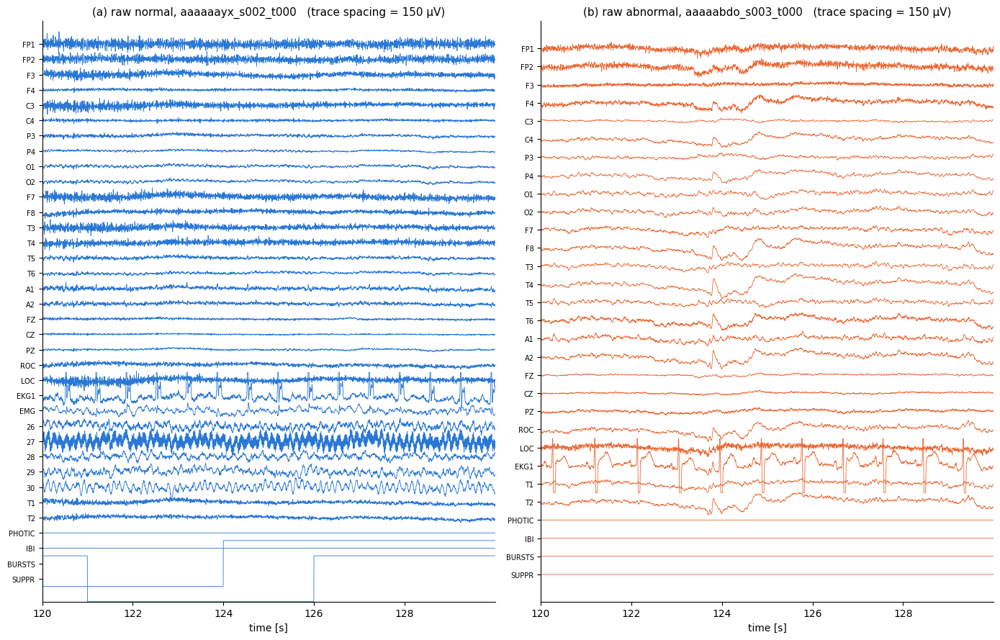

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["0 raw"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, color=CLASS_COLOR[label], spacing=150,
                 title=f"raw {CLASS_NAME[label]}, {stem}")
finish(fig, axes)

The spectrum is estimated with **Welch's method** (`scipy.signal.welch`, helper `welch_psd`):
the channel signal is cut into $M$ Hann-windowed segments of $L$ samples with 50 % overlap,

$$
\begin{aligned}
S_c(f) = \frac{2}{M\, f_s \sum_{n} w[n]^2}\sum_{m=1}^{M}\Big\lvert \sum_{n=0}^{L-1} w[n]\,\big(x_c[n + mL/2] - \bar x_{c,m}\big)\, e^{-j 2\pi f n / f_s}\Big\rvert^2
\end{aligned}
\tag{2.2}
$$

where $S_c(f)$ is the one-sided PSD of channel $c$ in µV²/Hz, $w$ the Hann window, $\bar x_{c,m}$ the
segment mean (constant detrend), and $L = 4 f_s$ (4 s, 0.25 Hz resolution) unless stated otherwise.
The **channel-averaged PSD** of a recording is

$$
S(f) = \frac{1}{C}\sum_{c=1}^{C} S_c(f)
\tag{2.3}
$$

over its $C = 23$ EEG channels. Figure 2.2 shows Eq. (2.3) for the two examples: a lot of power near
0 Hz (drift / DC), content all the way to the 125 Hz amplifier cut-off, and — very clearly in the
abnormal example — a sharp line at **60 Hz** (US power mains). Section 2.1 checks how typical this is.

### Figure 2.2. Raw spectrum of the two examples

Raw channel-averaged PSD, Eq. (2.3), of the two example recordings (23 EEG channels,
whole recording, 250 Hz).

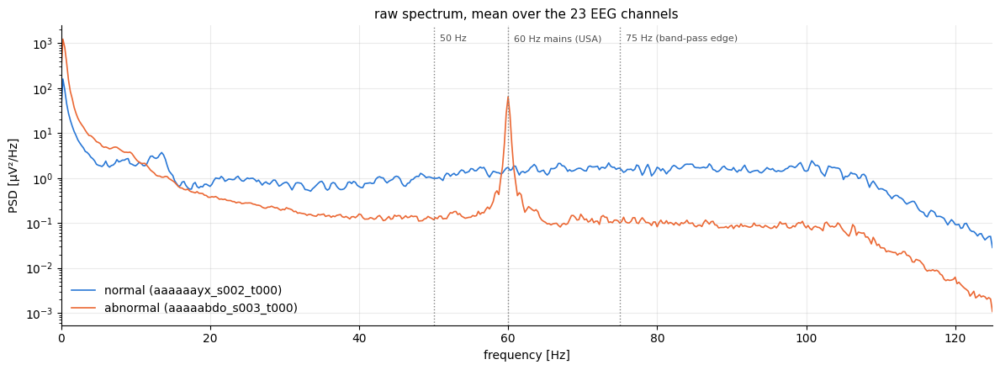

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for label, stem in examples.items():
    X, ch, sf = pipe[label][0]["0 raw"]
    eeg = [ch.index(c) for c in chOrder_standard]
    f, P = welch_psd(X[eeg], sf)
    ax.semilogy(f, P.mean(0), color=CLASS_COLOR[label], lw=1.2, label=f"{CLASS_NAME[label]} ({stem})")
for f0, txt in [(50, "50 Hz"), (60, "60 Hz mains (USA)"), (75, "75 Hz (band-pass edge)")]:
    ax.axvline(f0, color="0.5", ls=":", lw=1)
    ax.text(f0 + 0.8, 0.97, txt, fontsize=8, color="0.3", va="top", transform=ax.get_xaxis_transform())
ax.set_xlim(0, 125)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("PSD [µV²/Hz]")
ax.set_title("raw spectrum, mean over the 23 EEG channels")
ax.legend(loc="lower left")
finish(fig)

### 2.1 Grand-average PSD of the cohort and the 50 / 60 / 75 Hz peaks

Two recordings do not tell whether a spectral line is typical. We compute Eq. (2.3) for **every
recording of the test set** (`eval/`, both classes), once on the **raw** signal (step 1: 23 EEG
channels, native rate, unfiltered) and once on the **processed** windows stored by `make_TUAB.py`
(step 5: after band-pass, notch and resampling; up to `GA_WINDOWS` evenly spaced 10 s windows per
recording). Every recording PSD is interpolated onto a common 0.25 Hz grid. The **grand average** of
a group $\mathcal R$ of recordings is

$$
\bar S_{\mathcal R}(f) = \frac{1}{\lvert \mathcal R\rvert}\sum_{r \in \mathcal R} S_r(f)
\tag{2.4}
$$

where $S_r(f)$ is Eq. (2.3) of recording $r$ (µV²/Hz). Three statistics describe a spectral line at
$f_0 \in \{50, 60, 75\}$ Hz in one recording (helpers `line_prominence_db`, `line_power_db`):

$$
\Delta_r(f_0) = 10\log_{10}\frac{\max_{\lvert f - f_0\rvert \le 0.5} S_r(f)}{\operatorname{median}_{1 < \lvert f - f_0\rvert < 5} S_r(f)}
\tag{2.5}
$$

$$
\rho_r(f_0) = 10\log_{10}\frac{\int_{f_0 - 0.5}^{f_0 + 0.5} S_r(f)\,df}{\int_{1}^{45} S_r(f)\,df}
\tag{2.6}
$$

$$
\pi(f_0) = \frac{100}{\lvert \mathcal R\rvert}\sum_{r \in \mathcal R} \mathbb 1\big[\Delta_r(f_0) > \tau\big],\qquad \tau = 3\ \text{dB}
\tag{2.7}
$$

$\Delta_r$ (dB) is the **prominence**: how far the line sticks out of its own neighbourhood (0 dB = no
peak, negative = a notch). $\rho_r$ (dB) is the **line power relative to the 1–45 Hz EEG power**
(−10 dB = the line carries a tenth of the EEG power). $\pi$ (%) is the share of recordings with a
visible peak. Figure 2.3 shows Eq. (2.4), Figure 2.4 the distribution of Eq. (2.5), and Table 2.2
summarises Eqs. (2.5)–(2.7).

In [9]:
GA_WINDOWS = 20                                   # processed windows per recording (evenly spaced)
F_RAW = np.arange(0, 125.0 + 1e-9, 0.25)          # common grid, raw (Nyquist of 250 Hz)
F_PROC = np.arange(0, 100.0 + 1e-9, 0.25)         # common grid, processed (Nyquist of 200 Hz)


def grand_average_inputs():
    test_dir = PROCESSED / "test"
    by_stem = collections.defaultdict(list)
    if test_dir.exists():
        for fn in os.listdir(test_dir):
            stem, k = fn[:-4].rsplit("_", 1)
            by_stem[stem].append(int(k))
    out = dict(stem=[], y=[], sf=[], raw=[], proc=[], p99=[])
    for label, stems in ((0, eval_normal), (1, eval_abnormal)):
        for stem in stems:
            raw = mne.io.read_raw_edf(edf_path("eval", label, stem), preload=False)
            if not set(chOrder_standard) <= set(raw.ch_names):
                continue                                           # skipped by make_TUAB.py too
            raw.pick(chOrder_standard)
            x, sf = raw.get_data(units="uV"), raw.info["sfreq"]
            f, P = welch_psd(x, sf)
            S_raw = np.interp(F_RAW, f, P.mean(0), right=np.nan)  # Eq. (2.3) on the common grid
            S_proc, p99 = np.full(len(F_PROC), np.nan), np.nan
            if by_stem.get(stem):
                ks = sorted(by_stem[stem])
                pick = np.unique(np.linspace(0, len(ks) - 1, min(GA_WINDOWS, len(ks))).round().astype(int))
                Ws = []
                for j in pick:
                    with open(test_dir / f"{stem}_{ks[j]}.pkl", "rb") as fh:
                        Ws.append(pickle.load(fh)["X"])
                Ws = np.stack(Ws)                                  # [k, 23, 2000] µV
                f2, P2 = ss.welch(Ws, fs=TARGET_SFREQ, nperseg=4 * TARGET_SFREQ,
                                  noverlap=2 * TARGET_SFREQ, axis=-1)
                S_proc = np.interp(F_PROC, f2, P2.mean(axis=(0, 1)))
                p99 = np.percentile(np.abs(Ws), 99)
            for k_, v in zip(("stem", "y", "sf", "raw", "proc", "p99"), (stem, label, sf, S_raw, S_proc, p99)):
                out[k_].append(v)
    return {k_: np.array(v) for k_, v in out.items()}


GA = grand_average_inputs()
print(f"recordings: {len(GA['stem'])} (normal {np.sum(GA['y'] == 0)}, abnormal {np.sum(GA['y'] == 1)}); "
      f"with processed windows: {np.sum(~np.isnan(GA['proc'][:, 10]))}")
print("native sampling rates:", dict(collections.Counter(GA["sf"].tolist())))

recordings: 276 (normal 150, abnormal 126); with processed windows: 276
native sampling rates: {250.0: 268, 256.0: 8}


#### Figure 2.3. Grand-average PSD of the test set, raw vs processed

Grand-average PSD, Eq. (2.4), of all test recordings by class: (a) raw (step 1, 23 EEG
channels, native rate), (b) zoom of (a) on 40–85 Hz with every recording's Eq. (2.3) as a thin line;
(c) processed windows (step 5, 200 Hz), (d) zoom of (c). Shaded band = inter-quartile range across
recordings; dotted lines at 50, 60 and 75 Hz. The grand mean (thick line) lies above the IQR band because a
few high-amplitude (artefact-rich) recordings dominate the arithmetic mean of Eq. (2.4).

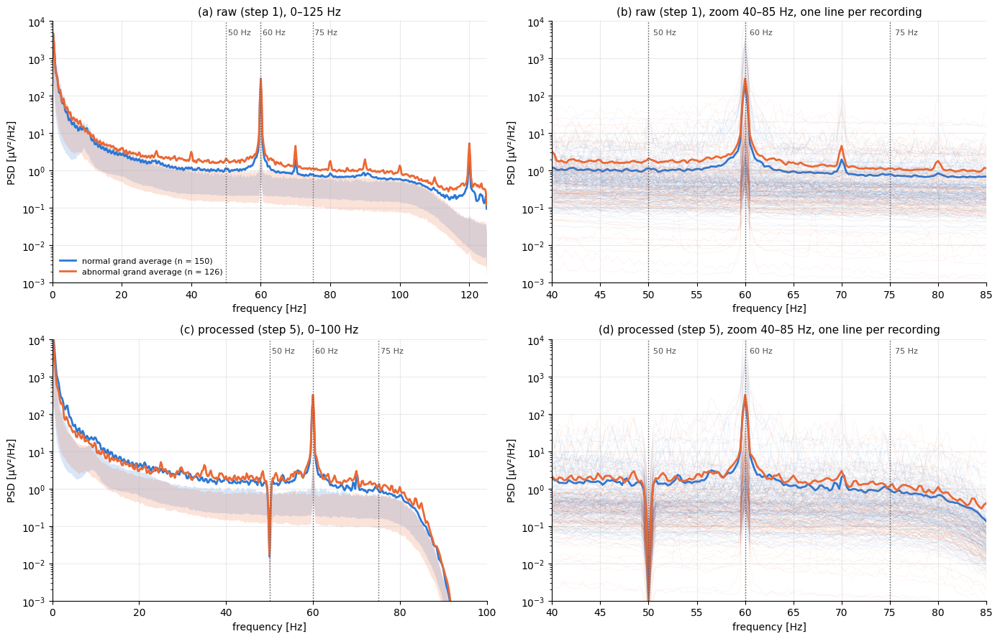

In [10]:
def ga_panel(ax, F, S, zoom=False):
    for label in (0, 1):
        Sg = S[GA["y"] == label]
        Sg = Sg[~np.isnan(Sg[:, 10])]
        if zoom:
            for s in Sg:
                ax.semilogy(F, s, color=CLASS_COLOR[label], lw=0.3, alpha=0.15)
        else:
            q25, q75 = np.nanpercentile(Sg, [25, 75], axis=0)
            ax.fill_between(F, q25, q75, color=CLASS_COLOR[label], alpha=0.18, lw=0)
        ax.semilogy(F, np.nanmean(Sg, axis=0), color=CLASS_COLOR[label], lw=2,
                    label=f"{CLASS_NAME[label]} grand average (n = {len(Sg)})")
    for f0 in (50, 60, 75):
        ax.axvline(f0, color="0.35", ls=":", lw=1)
        ax.text(f0 + 0.5, 0.97, f"{f0} Hz", fontsize=8, color="0.3", va="top", transform=ax.get_xaxis_transform())
    ax.set_xlim((40, 85) if zoom else (0, F[-1]))
    ax.set_xlabel("frequency [Hz]")
    ax.set_ylabel("PSD [µV²/Hz]")


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ga_panel(axes[0, 0], F_RAW, GA["raw"])
axes[0, 0].set_title("raw (step 1), 0–125 Hz")
ga_panel(axes[0, 1], F_RAW, GA["raw"], zoom=True)
axes[0, 1].set_title("raw (step 1), zoom 40–85 Hz, one line per recording")
ga_panel(axes[1, 0], F_PROC, GA["proc"])
axes[1, 0].set_title("processed (step 5), 0–100 Hz")
ga_panel(axes[1, 1], F_PROC, GA["proc"], zoom=True)
axes[1, 1].set_title("processed (step 5), zoom 40–85 Hz, one line per recording")
for ax in axes.ravel():
    ax.set_ylim(1e-3, 1e4)
axes[0, 0].legend(loc="lower left", fontsize=8)
finish(fig, list(axes.ravel()))

#### Figure 2.4. Line prominence at 50 / 60 / 75 Hz per test recording

Line prominence $\Delta_r(f_0)$, Eq. (2.5), per test recording at 50, 60 and 75 Hz, by
class: (a) raw (step 1), (b) processed (step 5). Boxes = quartiles, whiskers = 5th–95th percentile,
dots = recordings; dashed line = the $\tau = 3$ dB threshold of Eq. (2.7).

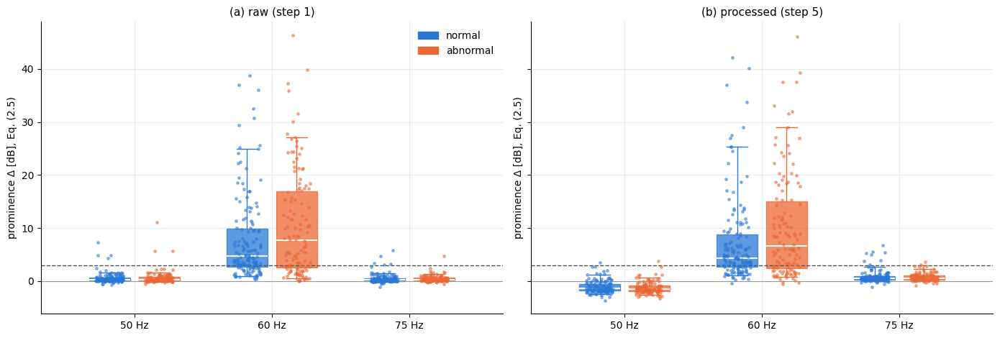

In [11]:
FREQS = (50, 60, 75)
stats_rows = []
D = {}
for stage, F, S in (("raw (step 1)", F_RAW, GA["raw"]), ("processed (step 5)", F_PROC, GA["proc"])):
    ok = ~np.isnan(S[:, 10])
    for f0 in FREQS:
        D[(stage, f0)] = np.array([line_prominence_db(F, s, f0) if k else np.nan for s, k in zip(S, ok)])
        D[(stage, f0, "rho")] = np.array([line_power_db(F, s, f0) if k else np.nan for s, k in zip(S, ok)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
rng = np.random.default_rng(0)
for ax, stage in zip(axes, ("raw (step 1)", "processed (step 5)")):
    for i, f0 in enumerate(FREQS):
        for j, label in enumerate((0, 1)):
            v = D[(stage, f0)][GA["y"] == label]
            v = v[~np.isnan(v)]
            pos = i + (j - 0.5) * 0.36
            bp = ax.boxplot(v, positions=[pos], widths=0.3, whis=(5, 95), showfliers=False,
                            patch_artist=True, medianprops=dict(color="white", lw=1.5))
            for b in bp["boxes"]:
                b.set(facecolor=CLASS_COLOR[label], edgecolor=CLASS_COLOR[label], alpha=0.75)
            for part in ("whiskers", "caps"):
                for l_ in bp[part]:
                    l_.set(color=CLASS_COLOR[label])
            ax.scatter(pos + rng.uniform(-0.1, 0.1, len(v)), v, s=6, color=CLASS_COLOR[label], alpha=0.5, zorder=3)
    ax.axhline(3, color="0.3", ls="--", lw=1)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xticks(range(len(FREQS)), [f"{f0} Hz" for f0 in FREQS])
    ax.set_ylabel("prominence Δ [dB], Eq. (2.5)")
    ax.set_title(stage)
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[l]) for l in (0, 1)],
               [CLASS_NAME[l] for l in (0, 1)], loc="upper right")
finish(fig, list(axes))

#### Table 2.2. Statistics of the 50, 60 and 75 Hz lines in the test set

One row per frequency and stage. `Δ` columns: median [inter-quartile range] of Eq. (2.5) in dB, per
class and overall; `π` = Eq. (2.7), % of recordings with $\Delta > 3$ dB; `ρ` = median [IQR] of
Eq. (2.6) in dB over all recordings.

In [12]:
def med_iqr(v):
    v = v[~np.isnan(v)]
    q25, q50, q75 = np.percentile(v, [25, 50, 75])
    return f"{q50:.1f} [{q25:.1f}, {q75:.1f}]"


rows = []
for f0 in FREQS:
    for stage in ("raw (step 1)", "processed (step 5)"):
        d, rho = D[(stage, f0)], D[(stage, f0, "rho")]
        ok = ~np.isnan(d)
        rows.append({"line": f"{f0} Hz", "stage": stage,
                     "Δ normal [dB]": med_iqr(d[GA["y"] == 0]),
                     "Δ abnormal [dB]": med_iqr(d[GA["y"] == 1]),
                     "Δ all [dB]": med_iqr(d),
                     "π: Δ > 3 dB [%]": 100 * np.mean(d[ok] > 3.0),
                     "ρ all [dB]": med_iqr(rho),
                     "n": int(ok.sum())})
peak_table = pd.DataFrame(rows).set_index(["line", "stage"])
display(numbered_table(peak_table, "2.2", "50/60/75 Hz line statistics", precision=1))

**Reading Figure 2.3, Figure 2.4 and Table 2.2.** The **60 Hz** mains line is present in most raw recordings and
is **not** removed by the pipeline (it is the same in the raw and processed rows of Table 2.2), because
the notch of step 3 sits at 50 Hz (section 5). At **50 Hz** there is no line in the raw data; after the notch the
processed spectra show a narrow dip (Figure 2.3(d)). $\Delta$ becomes only slightly negative, because the
notch (±0.125 Hz) is narrower than the ±0.5 Hz search band of Eq. (2.5). At **75 Hz** there is no line either; it is only
the start of the band-pass roll-off (Figure 4.1(c)), visible as the drop of the processed grand average
in Figure 2.3(c, d).

## 3. Step 1 — channel selection & ordering

`make_TUAB.py` defines a list $\mathcal D$ of channels to drop (`drop_channels`: EKG, EMG,
ROC/LOC, PHOTIC, IBI/BURSTS/SUPPR, RESP, `EEG 20-REF … EEG 128-REF`, …) and a fixed target
order $\mathcal O = (\mathcal O_1, \dots, \mathcal O_{23})$ of 23 channels (`chOrder_standard`):

$$
\begin{aligned}
\mathcal C_{\text{keep}} &= \mathcal C_{\text{raw}} \setminus \mathcal D,\qquad \lvert \mathcal C_{\text{keep}}\rvert = 23,\\
X^{(1)}_{i,:} &= X^{(0)}_{\pi(i),:},\qquad \pi(i) = \text{index of } \mathcal O_i \text{ in } \mathcal C_{\text{raw}}
\end{aligned}
\tag{3.1}
$$

where $\mathcal C_{\text{raw}}$ is the ordered channel list of the EDF and $X^{(0)}, X^{(1)}$ the signals
before and after this step. If after dropping the file does not contain exactly these 23 channels,
the recording is **skipped** and its name written to `tuab-process-error-files.txt` (Table 11.2 counts them).
Table 3.1 shows what is dropped for the two examples.

The 23 channels (Figure 3.1) are the 19 electrodes of the international 10-20 system
(Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, T6, Fz, Cz, Pz), the two ear
electrodes **A1/A2** and the anterior temporal electrodes **T1/T2**. Later, LaBraM maps each name
to its index in the 62-channel `standard_1020` list for the spatial position embedding (Table 8.1).

### Table 3.1. Channel selection for the two examples

In [13]:
rows = []
for label, stem in examples.items():
    _, ch_raw, _ = pipe[label][0]["0 raw"]
    dropped = [c for c in ch_raw if c in drop_channels]
    rows.append({"class": CLASS_NAME[label], "recording": stem, "raw channels": len(ch_raw),
                 "dropped": len(dropped), "kept": len(ch_raw) - len(dropped),
                 "dropped channels": ", ".join(short(c) for c in dropped)})
display(numbered_table(pd.DataFrame(rows).set_index("class"), "3.1", "channel selection", precision=0))
print("target order (23):", ", ".join(short(c) for c in chOrder_standard))

,recording,raw channels,dropped,kept,dropped channels
class,,,,,
normal,aaaaaayx_s002_t000,36,13,23,"ROC, LOC, EKG1, EMG, 26, 27, 28, 29, 30, PHOTIC, IBI, BURSTS, SUPPR"
abnormal,aaaaabdo_s003_t000,30,7,23,"ROC, LOC, EKG1, PHOTIC, IBI, BURSTS, SUPPR"


target order (23): FP1, FP2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, T6, A1, A2, FZ, CZ, PZ, T1, T2


### Figure 3.1. The 23 TUAB channels kept for LaBraM

Schematic scalp positions (nose up) of the 23 channels kept by Eq. (3.1): 19 standard
10-20 electrodes and the 4 extra ones (ear A1/A2, anterior temporal T1/T2, drawn at the rim).

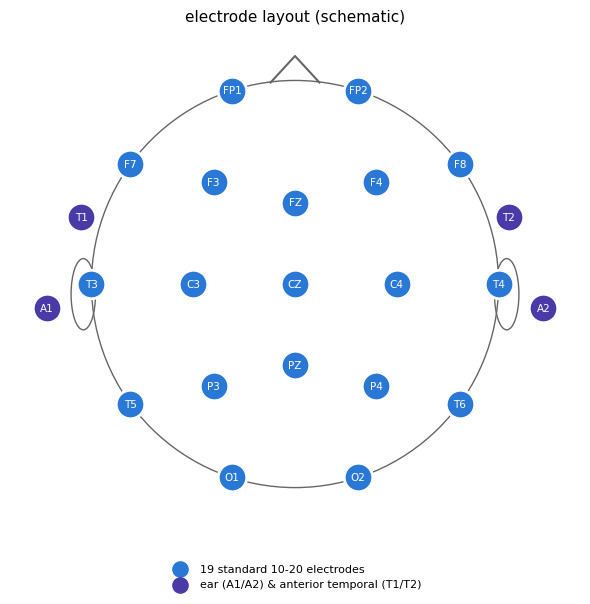

In [14]:
POS2D = {
    "FP1": (-0.31, 0.95), "FP2": (0.31, 0.95), "F7": (-0.81, 0.59), "F3": (-0.40, 0.50),
    "FZ": (0.0, 0.40), "F4": (0.40, 0.50), "F8": (0.81, 0.59), "T3": (-1.0, 0.0),
    "C3": (-0.50, 0.0), "CZ": (0.0, 0.0), "C4": (0.50, 0.0), "T4": (1.0, 0.0),
    "T5": (-0.81, -0.59), "P3": (-0.40, -0.50), "PZ": (0.0, -0.40), "P4": (0.40, -0.50),
    "T6": (0.81, -0.59), "O1": (-0.31, -0.95), "O2": (0.31, -0.95),
    "A1": (-1.22, -0.12), "A2": (1.22, -0.12), "T1": (-1.05, 0.33), "T2": (1.05, 0.33),
}
EXTRA = {"A1", "A2", "T1", "T2"}
C_EXTRA = "#4a3aa7"
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color="0.4"))
ax.plot([-0.12, 0, 0.12], [0.99, 1.12, 0.99], color="0.4")                       # nose
for side in (-1, 1):
    ax.add_patch(plt.matplotlib.patches.Ellipse((side * 1.04, -0.05), 0.12, 0.35, fill=False, color="0.4"))
for name in (short(c) for c in chOrder_standard):
    x_, y_ = POS2D[name]
    ax.scatter(x_, y_, s=420, color=C_EXTRA if name in EXTRA else C_NORMAL, edgecolor="white", lw=2, zorder=3)
    ax.text(x_, y_, name, ha="center", va="center", fontsize=7.5, color="white", zorder=4)
ax.scatter([], [], s=120, color=C_NORMAL, label="19 standard 10-20 electrodes")
ax.scatter([], [], s=120, color=C_EXTRA, label="ear (A1/A2) & anterior temporal (T1/T2)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("electrode layout (schematic)")
finish(fig)

### Figure 3.2. The 10 s window after channel selection (step 1)

The signal after step 1 — 23 EEG channels in the fixed order of Eq. (3.1), still 250 Hz
and unfiltered — for (a) the normal and (b) the abnormal example (same 10 s as Figure 2.1, µV).

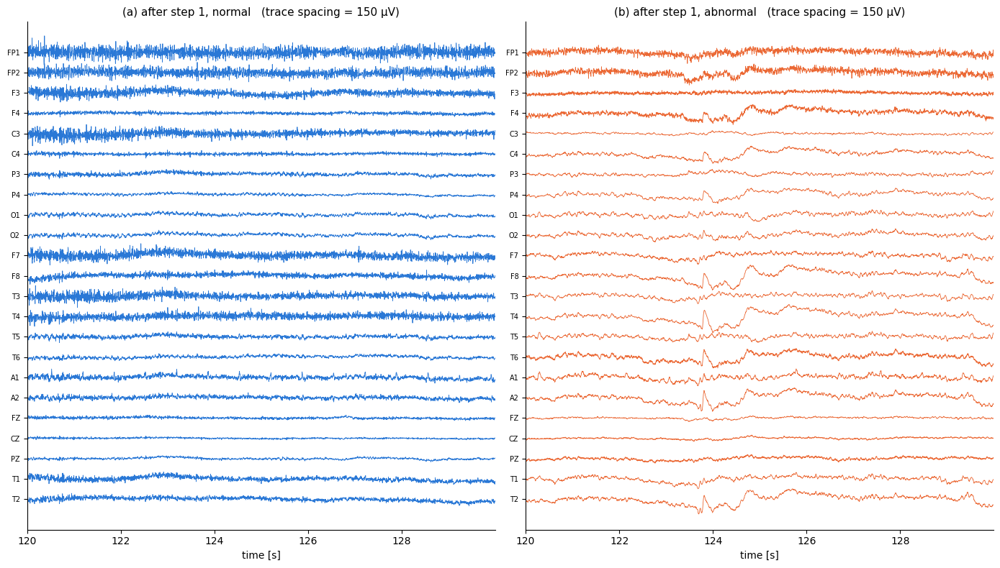

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["1 channels"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, color=CLASS_COLOR[label], spacing=150,
                 title=f"after step 1, {CLASS_NAME[label]}")
finish(fig, axes)

## 4. Step 2 — band-pass filter 0.1–75 Hz

`raw.filter(l_freq=0.1, h_freq=75.0)` uses MNE's defaults: a **linear-phase FIR** filter
designed with the **window method** (`firwin`, Hamming window) and applied with
**zero phase** (delay-compensated, non-causal).

**Design.** An ideal band-pass between $f_1$ and $f_2$ has the impulse response (difference of two ideal
low-passes)

$$
h_d[n] = \frac{2 f_2}{f_s}\operatorname{sinc}\!\Big(\frac{2 f_2 n}{f_s}\Big) - \frac{2 f_1}{f_s}\operatorname{sinc}\!\Big(\frac{2 f_1 n}{f_s}\Big),
\qquad \operatorname{sinc}(u) = \frac{\sin(\pi u)}{\pi u}
\tag{4.1}
$$

where $f_s = 250$ Hz and $f_1, f_2$ are the −6 dB cut-offs (Hz). It is truncated to $N$ taps and
multiplied by a Hamming window:

$$
h[n] = h_d\!\Big[n - \tfrac{N-1}{2}\Big]\, w[n],\qquad w[n] = 0.54 - 0.46\cos\!\Big(\frac{2\pi n}{N-1}\Big),\qquad n = 0, \dots, N-1
\tag{4.2}
$$

The cut-offs sit in the middle of the transition bands. MNE's automatic transition bandwidths for the
pass-band edges $f_l = 0.1$ Hz and $f_h = 75$ Hz are

$$
\begin{aligned}
\Delta f_{l} &= \min\!\big(\max(0.25\,f_l,\ 2),\ f_l\big), &
\Delta f_{h} &= \min\!\big(\max(0.25\,f_h,\ 2),\ \tfrac{f_s}{2} - f_h\big),\\
f_1 &= f_l - \tfrac{\Delta f_l}{2}, & f_2 &= f_h + \tfrac{\Delta f_h}{2}
\end{aligned}
\tag{4.3}
$$

and the filter length for a Hamming window is

$$
N = \Big\lceil 3.3\,\frac{f_s}{\min(\Delta f_l, \Delta f_h)} \Big\rceil\ \text{(rounded up to odd)}
\tag{4.4}
$$

Table 4.1 evaluates Eqs. (4.3)–(4.4). The very long filter (~33 s) is the price of the very narrow
transition at the low end.

**Application (zero phase).** Since $h$ is symmetric, centring it removes the $(N-1)/2$-sample delay:

$$
y[n] = \sum_{k=0}^{N-1} h[k]\; x\!\Big[n + \tfrac{N-1}{2} - k\Big]
\tag{4.5}
$$

where $x$ is the input (µV) and $y$ the filtered output (µV); the signal is padded at both ends by
reflection (`pad="reflect_limited"`) to reduce edge effects.

**Why.** Below 0.1 Hz there is no useful brain signal in a clinical EEG — only electrode
offset, sweat and movement drift. Above ~75 Hz the scalp EEG is dominated by muscle (EMG)
and instrument noise; 75 Hz also keeps the signal below the 100 Hz Nyquist frequency of
the 200 Hz target rate (step 4).

### Table 4.1. Parameters of the band-pass filter

Computed from Eqs. (4.3)–(4.4) and checked against the filter MNE actually designs
(`mne.filter.create_filter`, identical to `raw.filter`).

In [16]:
sf0 = 250.0
dfl = min(max(0.25 * L_FREQ, 2.0), L_FREQ)
dfh = min(max(0.25 * H_FREQ, 2.0), sf0 / 2 - H_FREQ)
N_eq = int(np.ceil(3.3 * sf0 / min(dfl, dfh)))
N_eq += (N_eq % 2 == 0)
h_bp = mne.filter.create_filter(None, sf0, L_FREQ, H_FREQ)
params = pd.DataFrame([
    ("pass-band edges f_l / f_h", f"{L_FREQ} / {H_FREQ} Hz", "(4.3)"),
    ("transition bandwidths Δf_l / Δf_h", f"{dfl:g} / {dfh:g} Hz", "(4.3)"),
    ("−6 dB cut-offs f_1 / f_2", f"{L_FREQ - dfl / 2:g} / {H_FREQ + dfh / 2:g} Hz", "(4.3)"),
    ("stop band starts below / above", f"{L_FREQ - dfl:g} / {H_FREQ + dfh:g} Hz", "(4.3)"),
    ("taps N (Eq.) / taps (MNE)", f"{N_eq} / {len(h_bp)}", "(4.4)"),
    ("filter length", f"{len(h_bp) / sf0:.1f} s", "(4.4)"),
    ("window / phase", "Hamming / zero phase", "(4.2), (4.5)"),
], columns=["quantity", "value", "Eq."]).set_index("quantity")
display(numbered_table(params, "4.1", "band-pass parameters"))

,value,Eq.
quantity,,
pass-band edges f_l / f_h,0.1 / 75.0 Hz,(4.3)
transition bandwidths Δf_l / Δf_h,0.1 / 18.75 Hz,(4.3)
−6 dB cut-offs f_1 / f_2,0.05 / 84.375 Hz,(4.3)
stop band starts below / above,0 / 93.75 Hz,(4.3)
taps N (Eq.) / taps (MNE),8251 / 8251,(4.4)
filter length,33.0 s,(4.4)
window / phase,Hamming / zero phase,"(4.2), (4.5)"


### Figure 4.1. Band-pass FIR 0.1–75 Hz (Hamming, zero phase)

The band-pass filter of Eqs. (4.1)–(4.5) at $f_s = 250$ Hz: (a) impulse response $h[n]$
(zoom ±0.2 s), (b) magnitude response $20\log_{10}\lvert H(f)\rvert$ on a log-frequency axis (dotted:
0.1 and 75 Hz), (c) the high-frequency edge on a linear axis with the transition band shaded.

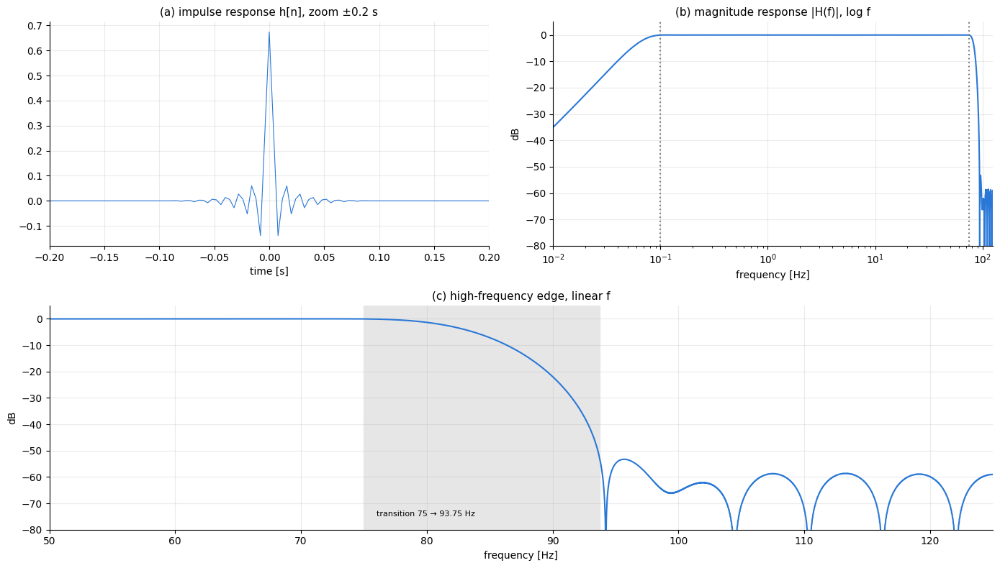

In [17]:
w, H = ss.freqz(h_bp, worN=2 ** 18, fs=sf0)
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2)
ax_a, ax_b, ax_c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
t_h = (np.arange(len(h_bp)) - (len(h_bp) - 1) / 2) / sf0
ax_a.plot(t_h, h_bp, color=C_AFTER, lw=0.8)
ax_a.set_xlim(-0.2, 0.2)
ax_a.set_title("impulse response h[n], zoom ±0.2 s")
ax_a.set_xlabel("time [s]")
ax_b.semilogx(w[1:], 20 * np.log10(np.abs(H[1:]) + 1e-12), color=C_AFTER)
ax_b.set_xlim(0.01, 125)
ax_b.set_ylim(-80, 5)
for fc in (L_FREQ, H_FREQ):
    ax_b.axvline(fc, color="0.5", ls=":")
ax_b.set_title("magnitude response |H(f)|, log f")
ax_b.set_xlabel("frequency [Hz]")
ax_b.set_ylabel("dB")
ax_c.plot(w, 20 * np.log10(np.abs(H) + 1e-12), color=C_AFTER)
ax_c.set_xlim(50, 125)
ax_c.set_ylim(-80, 5)
ax_c.axvspan(H_FREQ, H_FREQ + dfh, color="0.9", zorder=0)
ax_c.text(H_FREQ + 1, -75, f"transition {H_FREQ:g} → {H_FREQ + dfh:g} Hz", fontsize=8)
ax_c.set_title("high-frequency edge, linear f")
ax_c.set_xlabel("frequency [Hz]")
ax_c.set_ylabel("dB")
finish(fig, [ax_a, ax_b, ax_c])

### 4.1 Before vs after the band-pass on the same 10 s of real EEG

Figures 4.2–4.4 show the same **10 s window** as every other step (`SHOW_T0` … `SHOW_T0 + 10` s) before
(step 1) and after (step 2) the band-pass, at the same vertical scale. What the filter removed is

$$
r[n] = x[n] - y[n],\qquad \tilde r[n] = \frac{1}{f_s}\sum_{k = -f_s/2}^{f_s/2 - 1} r[n + k]
\tag{4.6}
$$

where $x$ is the step-1 signal, $y$ the band-passed signal of Eq. (4.5) (both µV), $r$ the removed
component and $\tilde r$ its 1 s moving average. Because the pass band is 0.1–75 Hz, $\tilde r$ is the
**slow drift / DC offset** (< 0.1 Hz) and $r - \tilde r$ is mostly the **> 75 Hz** content (muscle
activity, noise).

#### Figure 4.2. Cz before / after the band-pass and what was removed, 10 s

One channel (Cz), the 10 s window: before (grey, top), after (colour, middle) and the removed
component $r$ of Eq. (4.6) (bottom, with $\tilde r$ in black), for (a) the normal and (b) the abnormal
example. Traces are offset vertically; the scale bar is 50 µV. No display de-meaning except the
offsets, so drift is visible as wander of the top trace.

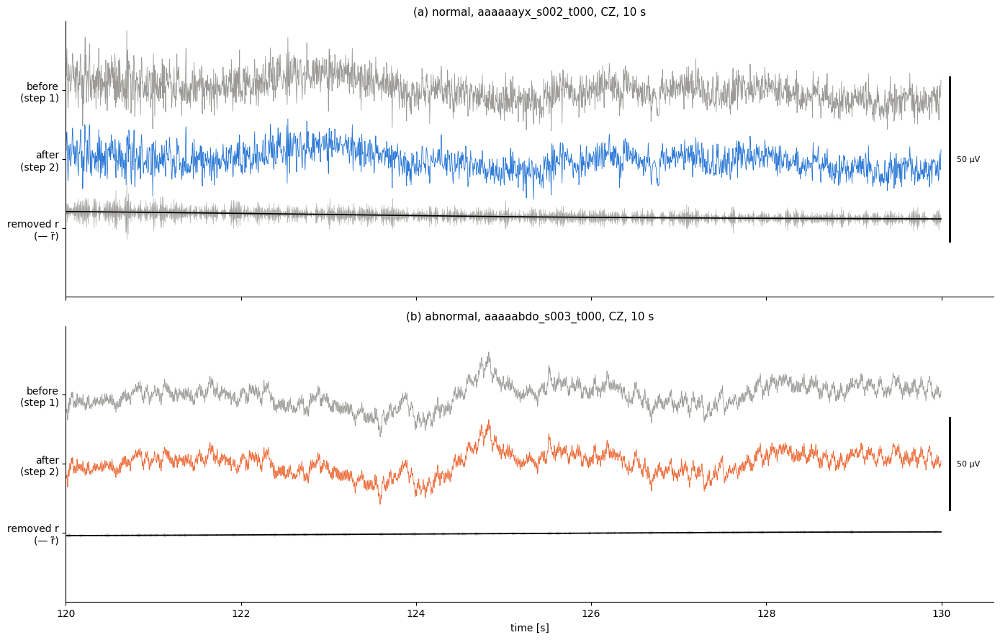

In [18]:
CH = "EEG CZ-REF"
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X1, ch, sf = pipe[label][0]["1 channels"]
    X2, _, _ = pipe[label][0]["2 band-pass"]
    i = ch.index(CH)
    i0, i1 = int(SHOW_T0 * sf), int((SHOW_T0 + SHOW_DUR) * sf)
    t = np.arange(i0, i1) / sf
    before, after = X1[i, i0:i1], X2[i, i0:i1]
    removed = before - after
    slow = np.convolve(X1[i] - X2[i], np.ones(int(sf)) / sf, mode="same")[i0:i1]
    off = 6 * np.std(after)
    ax.plot(t, before - np.median(before) + off, color=C_BEFORE, lw=0.6)
    ax.plot(t, after, color=CLASS_COLOR[label], lw=0.6)
    ax.plot(t, removed - off, color=C_BEFORE, lw=0.4)
    ax.plot(t, slow - off, color="k", lw=1.2)
    ax.set_yticks([off, 0, -off], ["before\n(step 1)", "after\n(step 2)", "removed r\n(— r̃)"])
    ax.plot([t[-1] + 0.1] * 2, [-25, 25], color="k", lw=2, clip_on=False)
    ax.text(t[-1] + 0.18, 0, "50 µV", va="center", fontsize=8)
    ax.set_xlim(t[0], t[-1] + 0.6)
    ax.set_ylim(-2 * off, 2 * off)
    ax.grid(False)
    ax.set_title(f"{CLASS_NAME[label]}, {stem}, {short(CH)}, 10 s")
axes[-1].set_xlabel("time [s]")
finish(fig, list(axes))

Figures 4.3 (normal) and 4.4 (abnormal) show all 23 channels of the same 10 s window, (a) before and (b) after
the band-pass. Same trace spacing (150 µV) in both panels and in every per-step figure; per-channel mean of the
window removed for display. The high-frequency fuzz (muscle) and the slow wander are gone in (b); the rhythmic
brain activity is unchanged.

#### Figure 4.3. Normal example: 10 s before vs after the band-pass

`aaaaaayx_s002_t000`, all 23 channels: (a) before the band-pass (step 1), (b) after it (step 2); spacing 150 µV.

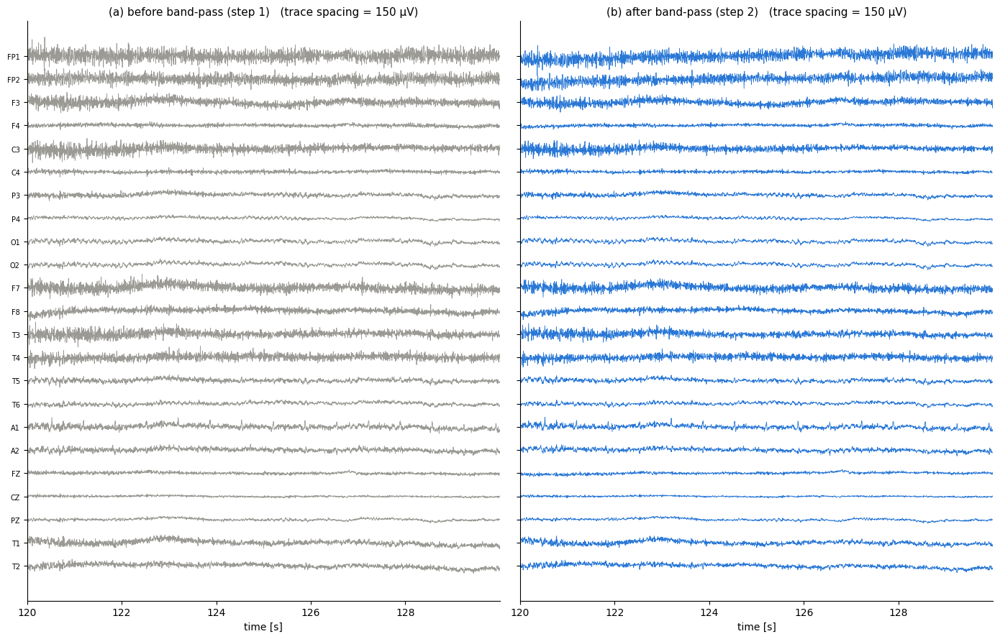

#### Figure 4.4. Abnormal example: 10 s before vs after the band-pass

`aaaaabdo_s003_t000`, all 23 channels: (a) before the band-pass (step 1), (b) after it (step 2); spacing 150 µV.

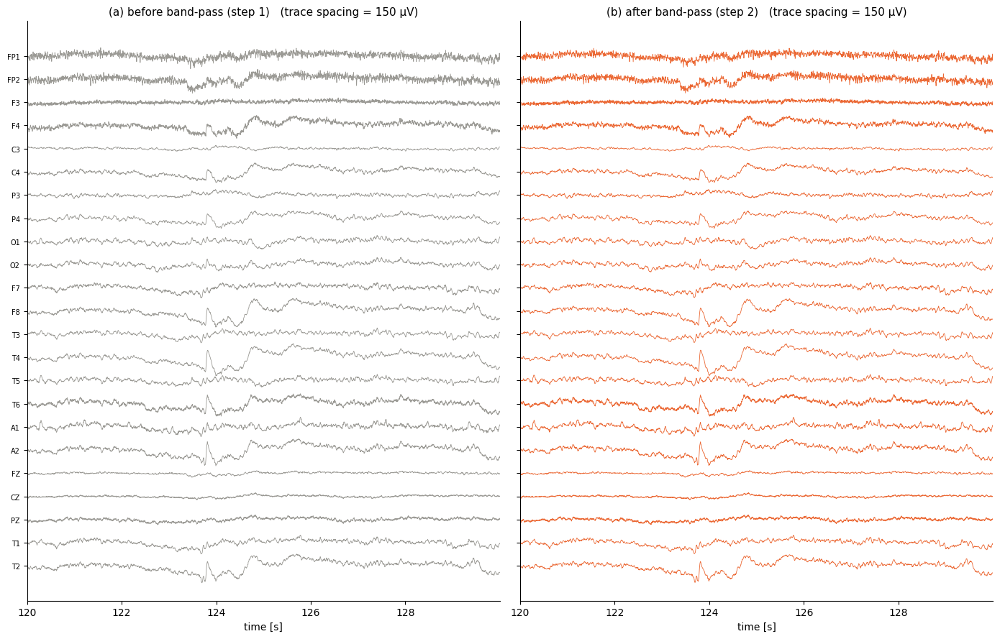

In [19]:
for number, label in (("4.3", 0), ("4.4", 1)):
    stem = examples[label]
    figure_heading(number, f"{CLASS_NAME[label].capitalize()} example: 10 s before vs after the band-pass",
                   note=f"`{stem}`, all 23 channels: (a) before the band-pass (step 1), (b) after it (step 2); "
                        "spacing 150 µV.", level=4)
    fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True, sharey=True)
    X1, ch, sf = pipe[label][0]["1 channels"]
    X2, _, _ = pipe[label][0]["2 band-pass"]
    plot_stacked(axes[0], X1, ch, sf, SHOW_T0, SHOW_DUR, spacing=150, color=C_BEFORE,
                 title="before band-pass (step 1)")
    plot_stacked(axes[1], X2, ch, sf, SHOW_T0, SHOW_DUR, spacing=150, color=CLASS_COLOR[label],
                 title="after band-pass (step 2)")
    finish(fig, list(axes))

#### Figure 4.5. Removed component r over the whole recording

The removed component $r$ of Eq. (4.6) for Cz over the **whole recording** (grey) and
its 1 s moving average $\tilde r$ (colour) for (a) the normal and (b) the abnormal example (µV). Bursts of
grey are muscle / movement artefacts (> 75 Hz content); the coloured line is the slow drift.

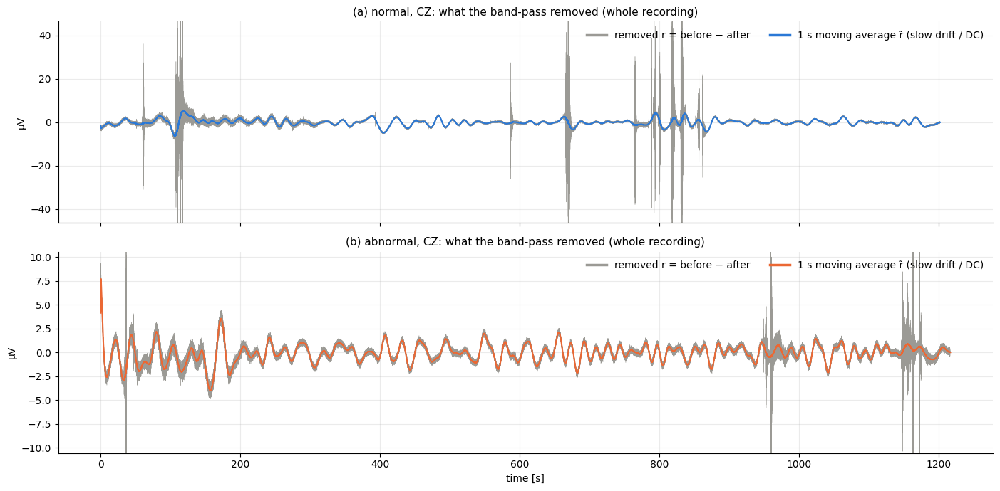

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X1, ch, sf = pipe[label][0]["1 channels"]
    X2, _, _ = pipe[label][0]["2 band-pass"]
    i = ch.index(CH)
    removed = X1[i] - X2[i]
    slow = np.convolve(removed, np.ones(int(sf)) / sf, mode="same")
    t = np.arange(len(removed)) / sf
    ax.plot(t, removed, color=C_BEFORE, lw=0.3, label="removed r = before − after")
    ax.plot(t, slow, color=CLASS_COLOR[label], lw=1.5, label="1 s moving average r̃ (slow drift / DC)")
    lim = np.percentile(np.abs(removed), 99.9) * 1.3
    ax.set_ylim(-lim, lim)
    ax.set_ylabel("µV")
    ax.set_title(f"{CLASS_NAME[label]}, {short(CH)}: what the band-pass removed (whole recording)")
    thick_legend(ax, loc="upper right", ncol=2)
axes[-1].set_xlabel("time [s]")
finish(fig, list(axes))

#### Figure 4.6. Spectrum before vs after the band-pass

Channel-averaged PSD, Eq. (2.3), before (grey) and after (colour) the band-pass for
(a) the normal and (b) the abnormal example (whole recording, 20 s Welch segments, log–log axes; dotted:
0.1 and 75 Hz).

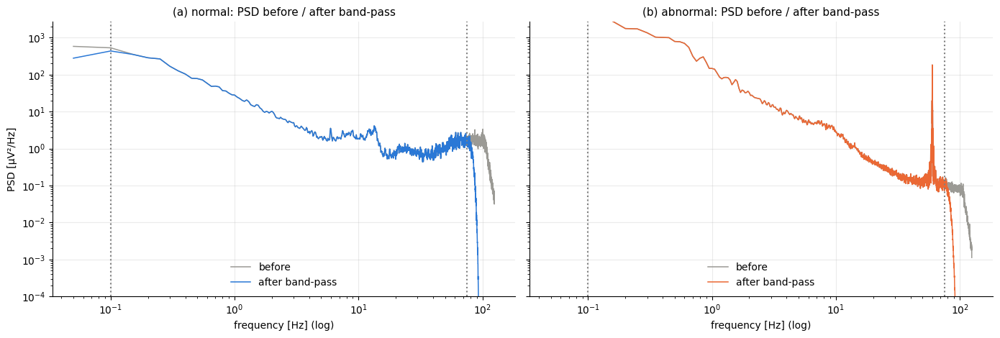

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (label, stem) in zip(axes, examples.items()):
    for st, col, nm in [("1 channels", C_BEFORE, "before"), ("2 band-pass", CLASS_COLOR[label], "after band-pass")]:
        X, ch, sf = pipe[label][0][st]
        f, P = welch_psd(X, sf, seg_sec=20.0)
        ax.loglog(f[1:], P.mean(0)[1:], color=col, lw=1.1, label=nm)
    for fc in (L_FREQ, H_FREQ):
        ax.axvline(fc, color="0.5", ls=":")
    ax.set_ylim(1e-4, None)
    ax.set_title(f"{CLASS_NAME[label]}: PSD before / after band-pass")
    ax.set_xlabel("frequency [Hz] (log)")
    ax.legend()
axes[0].set_ylabel("PSD [µV²/Hz]")
finish(fig, list(axes))

## 5. Step 3 — 50 Hz notch filter

`raw.notch_filter(50.0)` builds a narrow FIR **band-stop** filter (same window method, Hamming,
zero phase as Eqs. (4.2), (4.5)). With the defaults `notch_widths` $w = f_0/200 = 0.25$ Hz and
`trans_bandwidth` $\Delta f = 1$ Hz:

$$
h_{\text{notch}}[n] = \delta[n] - h_{\text{bp}}^{[f_0 - w/2,\ f_0 + w/2]}[n],\qquad
\lvert H_{\text{notch}}(f)\rvert \approx
\begin{cases}
0, & \lvert f - f_0\rvert \le w/2 \\
1, & \lvert f - f_0\rvert \ge w/2 + \Delta f/2
\end{cases}
\tag{5.1}
$$

where $f_0 = 50$ Hz, $\delta$ the unit impulse and $h_{\text{bp}}^{[a, b]}$ a band-pass of Eq. (4.2) between
$a$ and $b$. It removes a sliver of spectrum $50 \pm 0.125$ Hz and leaves everything outside
$\approx 49.4$–$50.6$ Hz untouched (Figure 5.1(a)).

> ⚠️ **TUH EEG was recorded in the USA, where the mains frequency is 60 Hz, not 50 Hz.**
> The 50 Hz notch therefore does essentially nothing on TUAB, and because the band-pass keeps
> everything up to 75 Hz, the **60 Hz line noise stays in the training data** (Figure 5.1(b),
> Table 5.1, and for the whole test set Table 2.2). The script was written for a mix of datasets; it is
> kept as-is here because the published checkpoints were trained on data processed exactly this way —
> changing it would change the input distribution.

### Figure 5.1. The 50 Hz notch and the surviving 60 Hz line

(a) Magnitude response of the 50 Hz notch, Eq. (5.1), at 250 Hz (dB); (b) channel-averaged
PSD, Eq. (2.3), around the line frequencies before (dotted) and after (solid) the notch for both examples.

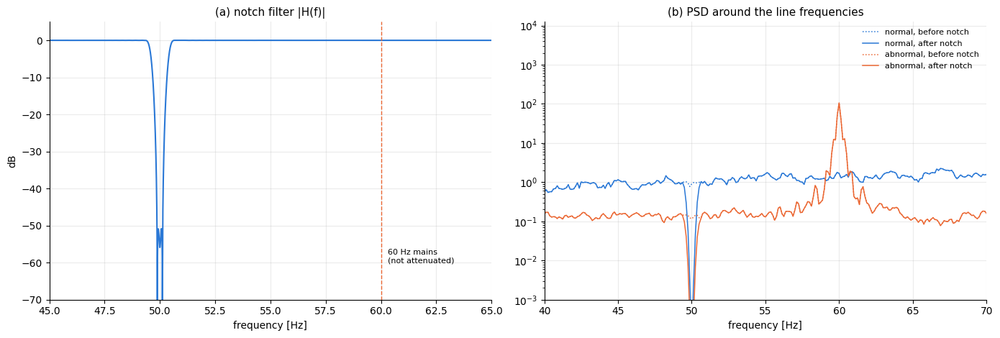

In [22]:
imp = np.zeros(2 ** 16)
imp[len(imp) // 2] = 1.0
h_notch = mne.filter.notch_filter(imp[np.newaxis], sf0, NOTCH_FREQ)[0]   # the very same function
Hn = np.fft.rfft(h_notch)
fn = np.fft.rfftfreq(len(h_notch), 1 / sf0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(fn, 20 * np.log10(np.abs(Hn) + 1e-12), color=C_AFTER)
axes[0].set_xlim(45, 65)
axes[0].set_ylim(-70, 5)
axes[0].axvline(60, color=C_ABNORMAL, ls="--", lw=1)
axes[0].text(60.3, -60, "60 Hz mains\n(not attenuated)", fontsize=8)
axes[0].set_title("notch filter |H(f)|")
axes[0].set_xlabel("frequency [Hz]")
axes[0].set_ylabel("dB")
for label, stem in examples.items():
    for st, ls_ in [("2 band-pass", ":"), ("3 notch", "-")]:
        X, ch, sf = pipe[label][0][st]
        f, P = welch_psd(X, sf, seg_sec=8.0)
        axes[1].semilogy(f, P.mean(0), color=CLASS_COLOR[label], ls=ls_, lw=1.1,
                         label=f"{CLASS_NAME[label]}, {'before' if st[0] == '2' else 'after'} notch")
axes[1].set_xlim(40, 70)
axes[1].set_ylim(1e-3, None)
axes[1].set_title("PSD around the line frequencies")
axes[1].set_xlabel("frequency [Hz]")
axes[1].legend(fontsize=8)
finish(fig, list(axes))

### Table 5.1. Line prominence before and after the notch for the two examples

Prominence $\Delta(f_0)$ of Eq. (2.5) in dB (8 s Welch segments), before (step 2) and after (step 3) the notch.

In [23]:
rows = []
for label, stem in examples.items():
    r = {"class": CLASS_NAME[label], "recording": stem}
    for f0 in (50, 60):
        for st, nm in (("2 band-pass", "before"), ("3 notch", "after")):
            X, ch, sf = pipe[label][0][st]
            f, P = welch_psd(X, sf, seg_sec=8.0)
            r[f"Δ({f0} Hz) {nm} [dB]"] = line_prominence_db(f, P, f0)
    rows.append(r)
display(numbered_table(pd.DataFrame(rows).set_index("class"), "5.1", "line prominence vs notch", precision=1))

,recording,Δ(50 Hz) before [dB],Δ(50 Hz) after [dB],Δ(60 Hz) before [dB],Δ(60 Hz) after [dB]
class,,,,,
normal,aaaaaayx_s002_t000,-0.3,-1.7,1.3,1.3
abnormal,aaaaabdo_s003_t000,0.0,-1.7,26.9,26.9


### Figure 5.2. The 10 s window after the 50 Hz notch (step 3)

The same 10 s window after step 3 (notch) for (a) the normal and (b) the abnormal example
(23 channels, 250 Hz, µV, spacing 150 µV). Visually identical to Figures 4.3(b)/4.4(b): the notch removes only
$50 \pm 0.125$ Hz, where TUAB has no line (Table 5.1).

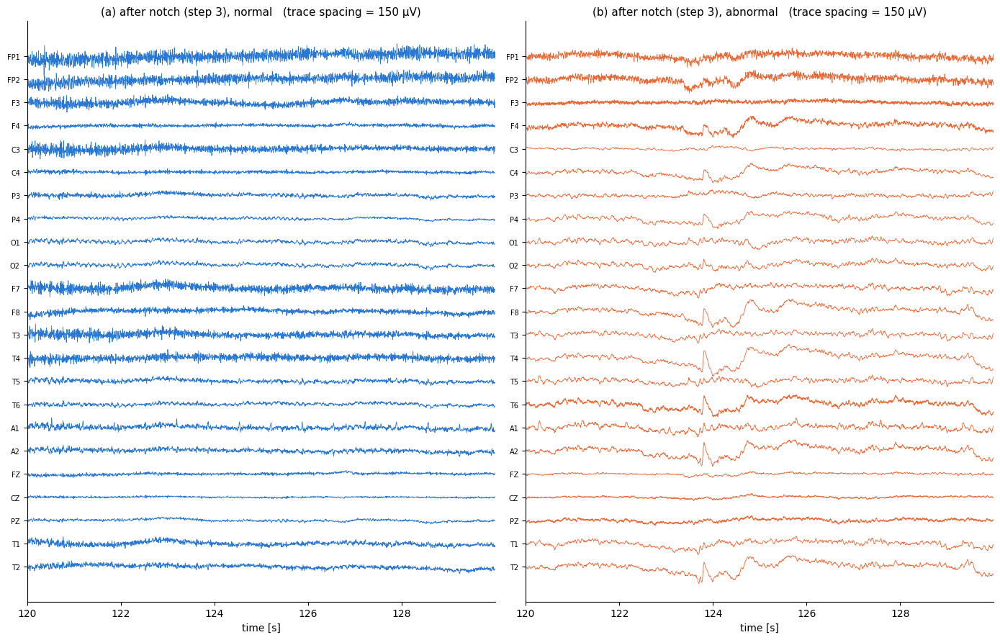

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["3 notch"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, spacing=150, color=CLASS_COLOR[label],
                 title=f"after notch (step 3), {CLASS_NAME[label]}")
finish(fig, list(axes))

## 6. Step 4 — resampling 250 → 200 Hz

LaBraM works with **200 samples per second** (one patch = 200 samples = 1 s) for all datasets.
`raw.resample(200)` uses MNE's **FFT (Fourier) method** with a boxcar window: the signal of
length $N$ is transformed, its spectrum is truncated to the new Nyquist band, and transformed
back with the new length $N'$:

$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N},\qquad N' = \operatorname{round}\!\Big(N\,\frac{f_s'}{f_s}\Big) = 0.8\,N
\tag{6.1}
$$

$$
x'[m] = \frac{N'}{N}\cdot\frac{1}{N'} \sum_{\lvert k\rvert < N'/2} X[k]\, e^{\,j 2\pi k m / N'},\qquad m = 0, \dots, N'-1
\tag{6.2}
$$

where $x$ (µV, $f_s = 250$ Hz) is the notch-filtered signal and $x'$ (µV, $f_s' = 200$ Hz) the resampled one;
the factor $N'/N$ keeps amplitudes unchanged. (The signal is first padded — `npad="auto"` to a fast FFT
length, edges by reflection.) Truncating the spectrum at the new Nyquist frequency $f_s'/2 = 100$ Hz is
an ideal anti-aliasing low-pass. Because step 2 already removed everything above ~85 Hz
(≥ 53 dB attenuation from 93.75 Hz, Table 4.1), nothing is aliased and the spectrum below 75 Hz is
unchanged (Figure 6.1(b, d)); Table 6.1 checks $N' = 0.8N$.

### Figure 6.1. FFT resampling 250 → 200 Hz

Resampling for the normal (top) and abnormal (bottom) example: (a, c) 0.5 s of Cz with
the 250 Hz samples (grey dots) and the 200 Hz samples (squares) — 5 samples ↔ 4 samples, same waveform;
(b, d) channel-averaged PSD, Eq. (2.3), before and after (dotted: new Nyquist 100 Hz).

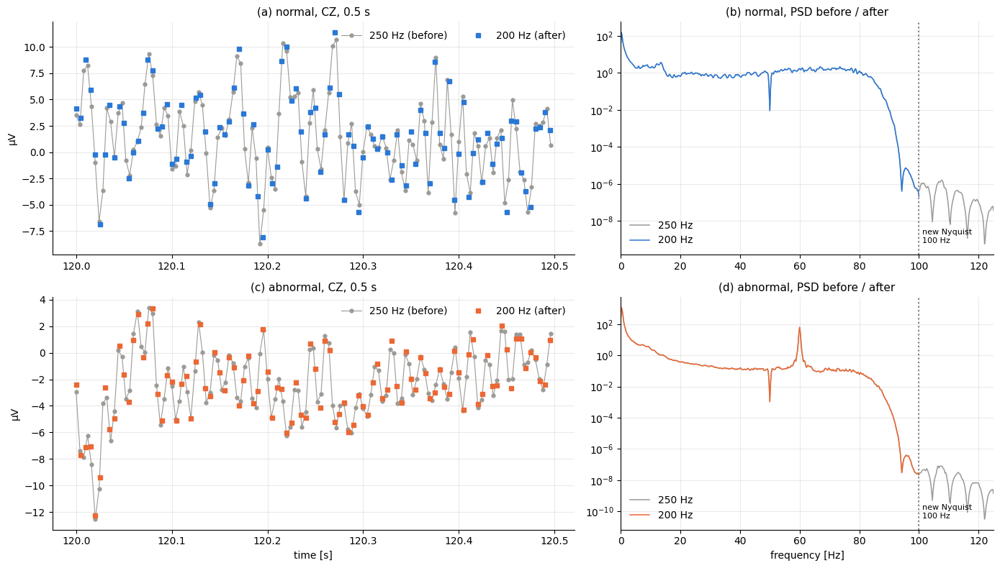

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.4, 1]})
rows = []
for row, (label, stem) in enumerate(examples.items()):
    X3, ch, sf3 = pipe[label][0]["3 notch"]
    X4, _, sf4 = pipe[label][0]["4 resampled"]
    i = ch.index(CH)
    t_a, t_b = SHOW_T0, SHOW_T0 + 0.5
    m3 = (np.arange(X3.shape[1]) / sf3 >= t_a) & (np.arange(X3.shape[1]) / sf3 < t_b)
    m4 = (np.arange(X4.shape[1]) / sf4 >= t_a) & (np.arange(X4.shape[1]) / sf4 < t_b)
    ax = axes[row, 0]
    ax.plot(np.arange(X3.shape[1])[m3] / sf3, X3[i, m3], "o-", ms=3.5, lw=0.8, color=C_BEFORE, label="250 Hz (before)")
    ax.plot(np.arange(X4.shape[1])[m4] / sf4, X4[i, m4], "s", ms=4, color=CLASS_COLOR[label], label="200 Hz (after)")
    ax.set_title(f"{CLASS_NAME[label]}, {short(CH)}, 0.5 s")
    ax.set_ylabel("µV")
    ax.legend(loc="upper right", ncol=2)
    ax = axes[row, 1]
    for X, sf, col, nm in [(X3, sf3, C_BEFORE, "250 Hz"), (X4, sf4, CLASS_COLOR[label], "200 Hz")]:
        f, P = welch_psd(X, sf, seg_sec=4.0)
        ax.semilogy(f, P.mean(0), color=col, lw=1.1, label=nm)
    ax.axvline(100, color="0.5", ls=":")
    ax.text(101, 0.05, "new Nyquist\n100 Hz", fontsize=8, transform=ax.get_xaxis_transform())
    ax.set_xlim(0, 125)
    ax.set_title(f"{CLASS_NAME[label]}, PSD before / after")
    ax.legend()
    rows.append({"class": CLASS_NAME[label], "N (250 Hz)": X3.shape[1], "N' (200 Hz)": X4.shape[1],
                 "N'/N": X4.shape[1] / X3.shape[1], "duration [s]": X4.shape[1] / sf4})
axes[1, 0].set_xlabel("time [s]")
axes[1, 1].set_xlabel("frequency [Hz]")
finish(fig, list(axes.ravel()))

### Table 6.1. Sample counts before and after resampling

$N$ and $N'$ of Eq. (6.1) for the two examples.

In [26]:
display(numbered_table(pd.DataFrame(rows).set_index("class"), "6.1", "sample counts", precision=4))

,N (250 Hz),N' (200 Hz),N'/N,duration [s]
class,,,,
normal,300500,240400,0.8000,1202.0000
abnormal,304250,243400,0.8000,1217.0000


### Figure 6.2. The 10 s window after resampling to 200 Hz (step 4)

The same 10 s window after step 4 (resampled to 200 Hz, 2000 samples per channel) for (a) the
normal and (b) the abnormal example (µV, spacing 150 µV).

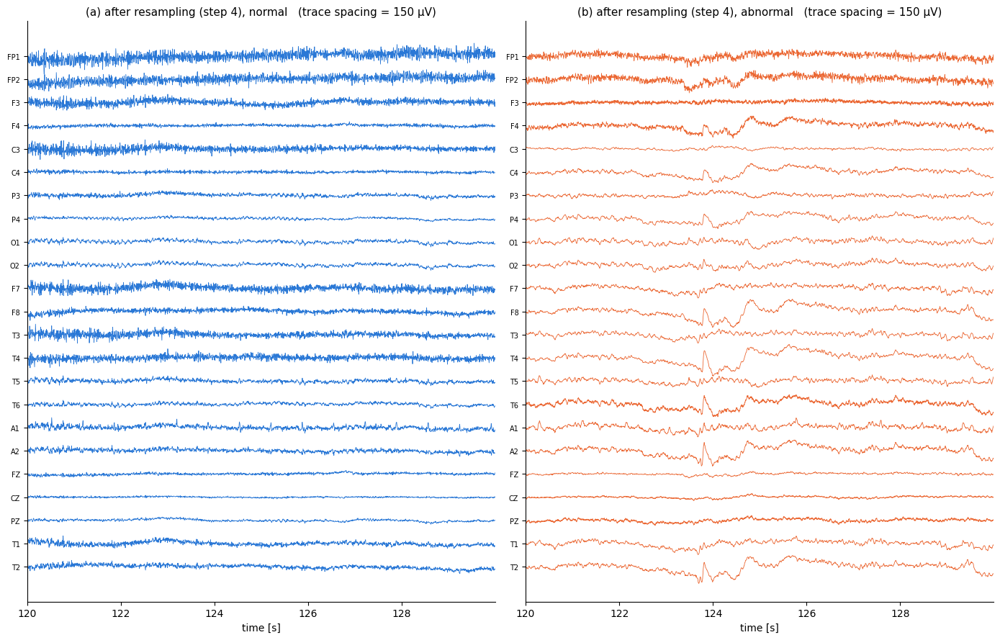

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["4 resampled"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, spacing=150, color=CLASS_COLOR[label],
                 title=f"after resampling (step 4), {CLASS_NAME[label]}")
finish(fig, list(axes))

## 7. Step 5 — windowing into 10 s samples, labels, verification

After resampling, the recording $X \in \mathbb R^{23 \times N'}$ (µV, 200 Hz) is cut into
**non-overlapping** windows of $W = 2000$ samples (10 s):

$$
K = \Big\lfloor \frac{N'}{W} \Big\rfloor,\qquad
X_k = X_{:,\ kW : (k+1)W} \in \mathbb R^{23\times 2000},\qquad y_k = y,\qquad k = 0, \dots, K-1
\tag{7.1}
$$

where $K$ is the number of windows, $y$ the recording label of section 1, and the last $N' \bmod W$
samples (< 10 s) are discarded (Figure 7.1). Every window is saved as

```python
pickle.dump({"X": X_k, "y": y}, open(f"processed/<split>/<stem>_<k>.pkl", "wb"))
```

There is **no** artefact rejection, re-referencing or amplitude normalisation in this offline
step — windows containing movement or electrode artefacts (the large bursts in Figure 7.1(a),
clipped by the y-axis) are kept as they are.

### Figure 7.1. Windowing a whole recording into 10 s samples

Whole recording, Cz after step 4 (µV), with the 10 s window boundaries of Eq. (7.1) (grey
lines) and the discarded tail (shaded), for (a) the normal and (b) the abnormal example.

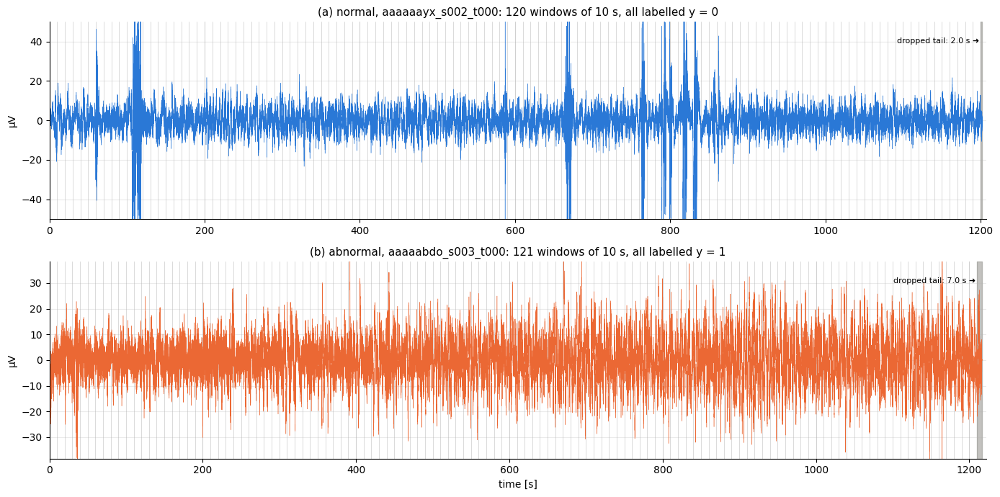

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["4 resampled"]
    i = ch.index(CH)
    K = X.shape[1] // WINDOW
    t = np.arange(X.shape[1]) / sf
    ax.plot(t, X[i], color=CLASS_COLOR[label], lw=0.3)
    for k in range(K + 1):
        ax.axvline(k * WINDOW / sf, color="0.75", lw=0.4, zorder=0)
    ax.axvspan(K * WINDOW / sf, t[-1], color=C_BEFORE, alpha=0.6)
    ax.text(K * WINDOW / sf - 2, 0.92, f"dropped tail: {(X.shape[1] - K * WINDOW) / sf:.1f} s ➜",
            fontsize=8, ha="right", va="top", transform=ax.get_xaxis_transform())
    lim = np.percentile(np.abs(X[i]), 99.5) * 1.5
    ax.set_ylim(-lim, lim)
    ax.set_xlim(0, t[-1] + 5)
    ax.set_ylabel("µV")
    ax.set_title(f"{CLASS_NAME[label]}, {stem}: {K} windows of 10 s, all labelled y = {label}")
axes[-1].set_xlabel("time [s]")
finish(fig, list(axes))

### Table 7.1. Notebook re-implementation vs the pickles stored by `make_TUAB.py`

`make_TUAB.py` puts each recording in exactly one of `processed/{train,val,test}`. For every window $k$
of the two examples we compare the stored array $X^{\text{stored}}_k$ with ours, $X_k$ of Eq. (7.1):

$$
\varepsilon = \max_{k}\ \max_{c, t}\ \big\lvert X^{\text{stored}}_{k, c, t} - X_{k, c, t}\big\rvert
\tag{7.2}
$$

in µV; `stored y` lists the labels found in the pickles and `extra window on disk` flags a window beyond $K$.

In [29]:
def find_processed(stem):
    for split in ("train", "val", "test"):
        if (PROCESSED / split / f"{stem}_0.pkl").exists():
            return split
    return None

rows = []
if PROCESSED.exists():
    for label, stem in examples.items():
        split = find_processed(stem)
        if split is None:
            rows.append({"class": CLASS_NAME[label], "recording": stem, "split": "not found"})
            continue
        windows = pipe[label][1]
        diffs, labels = [], set()
        for k in range(len(windows)):
            with open(PROCESSED / split / f"{stem}_{k}.pkl", "rb") as fh:
                s = pickle.load(fh)
            diffs.append(np.abs(s["X"] - windows[k]).max())
            labels.add(int(s["y"]))
        rows.append({"class": CLASS_NAME[label], "recording": stem, "split": split, "windows K": len(windows),
                     "ε [µV], Eq. (7.2)": f"{max(diffs):.1e}", "stored y": sorted(labels),
                     "extra window on disk": (PROCESSED / split / f"{stem}_{len(windows)}.pkl").exists()})
    display(numbered_table(pd.DataFrame(rows).set_index("class"), "7.1", "verification", precision=0))
else:
    print("processed/ folder not found — skipping verification")

,recording,split,windows K,"ε [µV], Eq. (7.2)",stored y,extra window on disk
class,,,,,,
normal,aaaaaayx_s002_t000,test,120,3.4e-13,[0],False
abnormal,aaaaabdo_s003_t000,test,121,1.8e-12,[1],False


### Figure 7.2. The stored 10 s window (step 5)

The stored pickle of the same 10 s window, `<stem>_<k>.pkl` with $k$ = `SHOW_T0`/10, read back from
`processed/` (step 5, the array the loader returns), for (a) the normal and (b) the abnormal example (µV,
spacing 150 µV). It equals Figure 6.2 to within $arepsilon$ of Table 7.1.

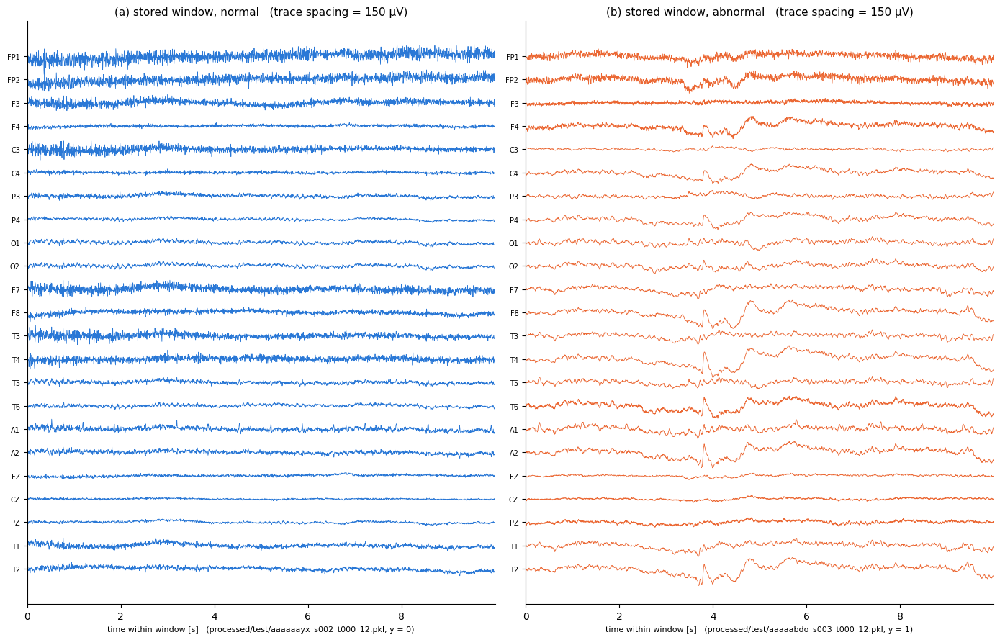

In [30]:
k_show = int(SHOW_T0 // 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    split = find_processed(stem)
    if split is not None:
        with open(PROCESSED / split / f"{stem}_{k_show}.pkl", "rb") as fh:
            s = pickle.load(fh)
        Xw, src = s["X"], f"processed/{split}/{stem}_{k_show}.pkl, y = {s['y']}"
    else:
        Xw, src = pipe[label][1][k_show], f"window {k_show} (re-computed)"
    plot_stacked(ax, Xw, chOrder_standard, TARGET_SFREQ, 0, SHOW_DUR, spacing=150, color=CLASS_COLOR[label],
                 title=f"stored window, {CLASS_NAME[label]}")
    ax.set_xlabel(f"time within window [s]   ({src})", fontsize=8)
finish(fig, list(axes))

## 8. Step 6 — what the model actually receives

At training/evaluation time the `TUABLoader` reads a pickle and returns
`(torch.FloatTensor(X), y)` (it would resample to another rate only if `sampling_rate ≠ 200`).
Then `train_finetune.py` does two more things:

```python
samples = samples.float() / 100                                    # µV -> units of 100 µV
samples = rearrange(samples, 'B N (A T) -> B N A T', T=200)        # 1 s patches
```

$$
\tilde x_{c,a,t} = \frac{X_{c,\;200a + t}}{100},\qquad c = 1, \dots, 23,\quad a = 0, \dots, 9,\quad t = 0, \dots, 199
\tag{8.1}
$$

where $X$ is one stored window (µV), $a$ the patch index and $t$ the sample within the patch;
$\tilde x$ is in units of 100 µV.

* **Scaling by 1/100** brings typical EEG amplitudes (tens of µV) to $O(0.1$–$1)$ — a fixed,
  global scale (no per-sample normalisation), identical to pre-training.
* **Patching**: each channel's 10 s window becomes 10 patches of 1 s → 23 × 10 = 230 tokens.
  Each patch is embedded by the temporal convolution; LaBraM adds a **temporal embedding**
  (patch index $a$) and a **spatial embedding** chosen by the electrode's position in the 62-channel
  `standard_1020` list (`labram.data.eeg_constants.get_channel_indices`):

$$
\iota_c = 1 + \operatorname{index}\big(\text{name}_c \text{ in } \texttt{standard\_1020}\big),\qquad \iota_0 = 0\ \text{(CLS token)}
\tag{8.2}
$$

Table 8.1 lists $\iota_c$. Figure 8.1(b) colours each token by its patch RMS,

$$
\operatorname{RMS}_{c,a} = \sqrt{\frac{1}{200}\sum_{t=0}^{199} \tilde x_{c,a,t}^{\,2}}
\tag{8.3}
$$

in units of 100 µV.

### Table 8.1. Spatial-embedding index of each TUAB channel

`ι` = Eq. (8.2); the CLS token has index 0.

In [31]:
import torch
from einops import rearrange
from labram.data.eeg_constants import get_channel_indices, normalize_ch_names, TUH_EEG_CH_NAMES

ch_names = normalize_ch_names(TUH_EEG_CH_NAMES)
assert ch_names == [short(c) for c in chOrder_standard]
iota = get_channel_indices(ch_names)
display(numbered_table(pd.DataFrame({"channel": ["CLS"] + ch_names, "ι": iota}).set_index("channel").T,
                       "8.1", "spatial-embedding index", precision=0))

channel,CLS,FP1,FP2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,A1,A2,FZ,CZ,PZ,T1,T2
ι,0,1,3,18,22,40,44,62,66,81,83,16,24,89,91,90,92,95,96,20,42,64,113,114


### Figure 8.1. Model input of the abnormal example's window (step 6)

Model input for one window of the abnormal example (the 10 s starting at `SHOW_T0`):
(a) Cz after Eq. (8.1) (units of 100 µV), alternate 1 s patches shaded; (b) the 23 × 10 = 230 input tokens,
coloured by $\operatorname{RMS}_{c,a}$ of Eq. (8.3).

one window (23, 2000) µV  ->  model input (1, 23, 10, 200) (B, channels, patches, samples)
value range after /100: min -1.17, max 0.88, std 0.208


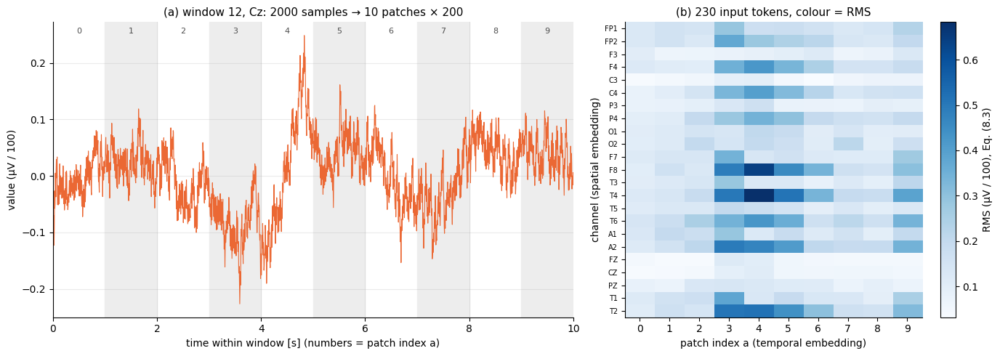

In [32]:
label = 1
windows = pipe[label][1]
k_show = int(SHOW_T0 // 10)                       # the window containing the excerpt shown above
x = torch.FloatTensor(windows[k_show])[None] / 100
xp = rearrange(x, "B N (A T) -> B N A T", T=PATCH)
print(f"one window {tuple(windows[k_show].shape)} µV  ->  model input {tuple(xp.shape)} (B, channels, patches, samples)")
print(f"value range after /100: min {xp.min():.2f}, max {xp.max():.2f}, std {xp.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
sig = x[0, ch_names.index("CZ")].numpy()
ax.plot(np.arange(len(sig)) / TARGET_SFREQ, sig, color=CLASS_COLOR[label], lw=0.8)
for a in range(10):
    if a % 2:
        ax.axvspan(a, a + 1, color="0.93", zorder=0)
    ax.text(a + 0.5, 0.98, f"{a}", ha="center", va="top", fontsize=8, color="0.3",
            transform=ax.get_xaxis_transform())
ax.set_xlim(0, 10)
ax.set_xlabel("time within window [s] (numbers = patch index a)")
ax.set_ylabel("value (µV / 100)")
ax.set_title(f"window {k_show}, Cz: 2000 samples → 10 patches × 200")
ax = axes[1]
rms = xp[0].pow(2).mean(-1).sqrt().numpy()
im = ax.imshow(rms, aspect="auto", cmap="Blues")
ax.set_yticks(range(23), ch_names, fontsize=7)
ax.set_xticks(range(10))
ax.set_xlabel("patch index a (temporal embedding)")
ax.set_ylabel("channel (spatial embedding)")
ax.grid(False)
ax.set_title("230 input tokens, colour = RMS")
fig.colorbar(im, ax=ax, label="RMS (µV / 100), Eq. (8.3)")
finish(fig, list(axes))

## 9. Step 7 (optional) — LaBraM++ preprocessing: CAR + per-patch z-score

Off by default. With `labram_plus.enabled=true` (see `docs/labram_plus_plus.md`) the model
itself applies two more transforms to every patch tensor $x \in \mathbb R^{B\times N\times A\times T}$
(`labram/data/preprocess.py`), first CAR then z-scoring.

**Common average reference** (`common_average_reference`) — subtract the instantaneous mean over the
$N$ electrodes:

$$
x^{\text{CAR}}_{b,c,a,t} = x_{b,c,a,t} - \frac{1}{N}\sum_{c'=1}^{N} x_{b,c',a,t}
\tag{9.1}
$$

**Per-patch z-score** (`z_score_per_patch`) — standardise each (channel, patch) over its $T = 200$ samples:

$$
\begin{aligned}
z_{b,c,a,t} &= \frac{x^{\text{CAR}}_{b,c,a,t} - \mu_{b,c,a}}{\sigma_{b,c,a} + \varepsilon},\\
\mu_{b,c,a} &= \frac{1}{T}\sum_t x^{\text{CAR}}_{b,c,a,t},\qquad
\sigma_{b,c,a} = \sqrt{\frac{1}{T-1}\sum_t \big(x^{\text{CAR}}_{b,c,a,t} - \mu_{b,c,a}\big)^2}
\end{aligned}
\tag{9.2}
$$

where $b$ is the batch index, $c$ the channel, $a$ the patch, $t$ the sample, and $\varepsilon = 10^{-5}$;
$z$ is unitless (σ units). Eq. (9.2) removes per-patch amplitude information entirely (every patch has
unit variance) — it equalises channels but hides "this patch is larger than usual" (Figure 9.1(c)).

### Figure 9.1. LaBraM++ preprocessing of the same window (step 7)

LaBraM++ preprocessing of the window of Figure 8.1: (a) model input of Eq. (8.1) (shown
×100, µV), (b) after CAR, Eq. (9.1) (µV), (c) after the per-patch z-score, Eq. (9.2) (σ; grey lines = patch
boundaries).

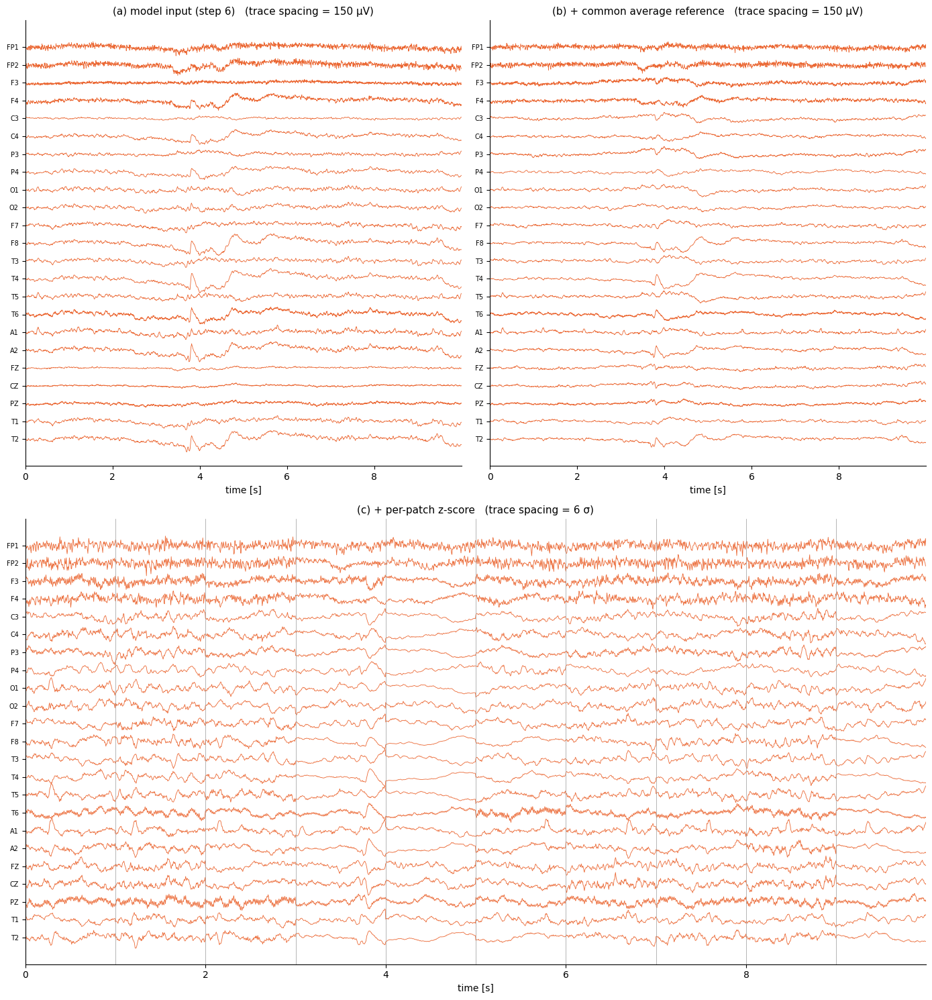

In [33]:
from labram.data.preprocess import common_average_reference, z_score_per_patch

x_car = common_average_reference(xp)
x_z = z_score_per_patch(x_car)

def flat(t):
    return rearrange(t, "B N A T -> B N (A T)")[0].numpy() * 100   # back to µV for display

fig = plt.figure(figsize=(14, 15))
gs = fig.add_gridspec(2, 2)
ax_a, ax_b, ax_c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
plot_stacked(ax_a, flat(xp), chOrder_standard, TARGET_SFREQ, 0, 10, spacing=150, color=C_ABNORMAL,
             title="model input (step 6)")
plot_stacked(ax_b, flat(x_car), chOrder_standard, TARGET_SFREQ, 0, 10, spacing=150, color=C_ABNORMAL,
             title="+ common average reference")
plot_stacked(ax_c, flat(x_z) / 100, chOrder_standard, TARGET_SFREQ, 0, 10, spacing=6, color=C_ABNORMAL,
             title="+ per-patch z-score", unit="σ")
for a in range(1, 10):
    ax_c.axvline(a, color="0.6", lw=0.5)
finish(fig, [ax_a, ax_b, ax_c])

## 10. Normal vs abnormal: examples and class-level spectra

### 10.1 Gallery

Three normal and three abnormal recordings from the test set (Figures 10.1–10.6). For each we show
(a) the **raw** signal (step 0, 23 EEG channels only, 250 Hz) next to (b) the **final 10 s window** stored
on disk (after step 5), at the same trace spacing.

Which window to show? The first window is biased toward set-up artefacts, and the cleanest one would be
cherry-picking. We show a **typical window**:

$$
k^{\ast} = \operatorname{argmedian}_{k}\ q_{99}\big(\lvert X_k\rvert\big)
\tag{10.1}
$$

where $q_{99}(\lvert X_k\rvert)$ is the 99th percentile of the absolute amplitude (µV) of window $k$ over all
channels and samples, and argmedian picks the window whose value is the median over the recording.

What to look for (clinical heuristics, not a rule — many abnormal EEGs look normal in any
given 10 s): normal adult EEG typically has a clear **posterior alpha rhythm (8–13 Hz)** at
O1/O2/P3/P4 during relaxed wakefulness; abnormal recordings more often show **slowing**
(excess delta 0.5–4 Hz / theta 4–8 Hz), focal or asymmetric activity, or epileptiform
discharges (spikes / sharp waves). Raw and processed windows look **very similar** at this scale: the
pipeline removes drift, > 75 Hz content and resamples — it does not "clean" the EEG of artefacts.

Figures 10.1–10.6 show one figure per recording (10.1–10.3 normal, 10.4–10.6 abnormal): (a) raw, step 0,
at the time of the typical window $k^\ast$ of Eq. (10.1); (b) the stored window `<stem>_<k*>.pkl` (µV).

#### Figure 10.1. Normal recording aaaaaayx_s002_t000

120 windows; typical window k* = 29 (Eq. (10.1)): (a) raw, (b) stored.

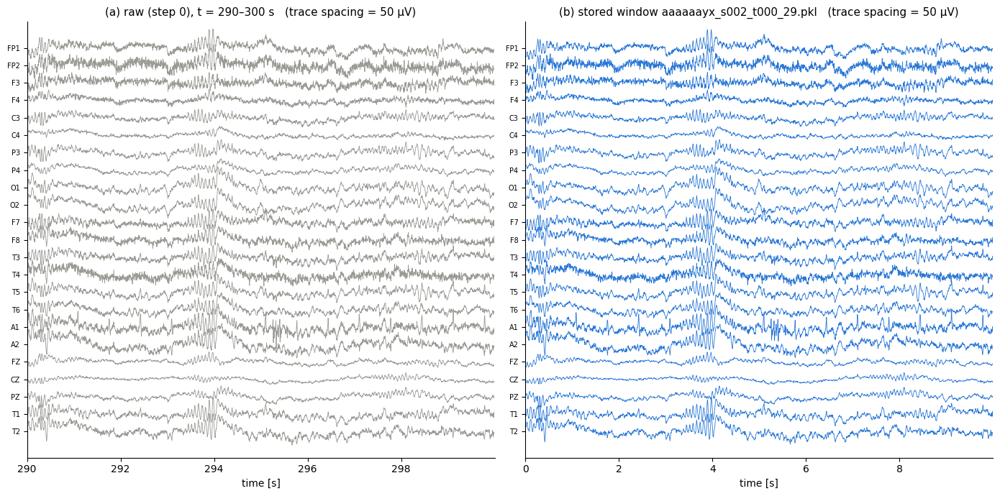

#### Figure 10.2. Normal recording aaaaacad_s003_t000

125 windows; typical window k* = 51 (Eq. (10.1)): (a) raw, (b) stored.

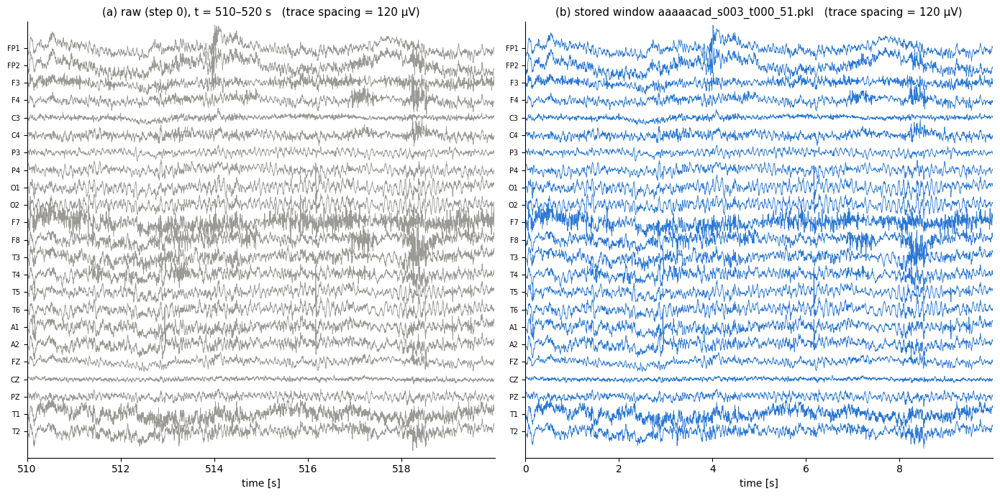

#### Figure 10.3. Normal recording aaaaacby_s004_t000

120 windows; typical window k* = 26 (Eq. (10.1)): (a) raw, (b) stored.

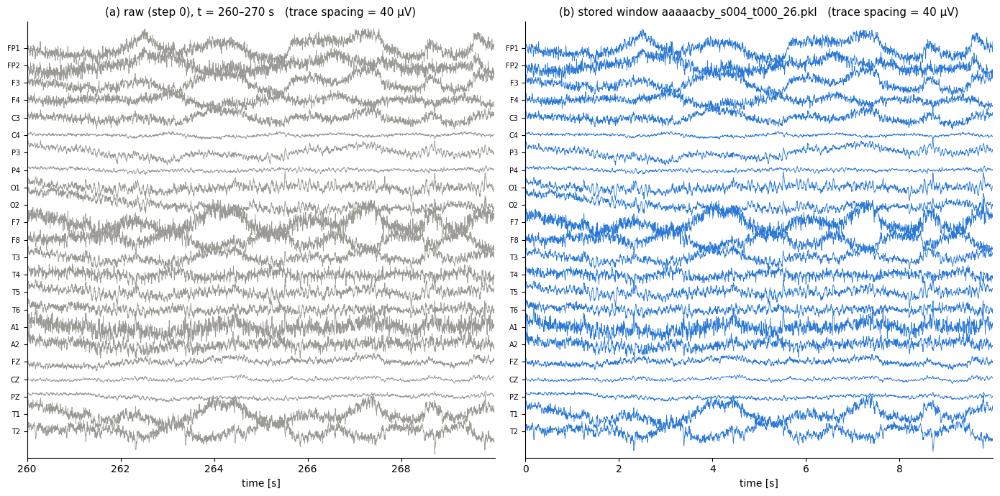

#### Figure 10.4. Abnormal recording aaaaabdo_s003_t000

121 windows; typical window k* = 40 (Eq. (10.1)): (a) raw, (b) stored.

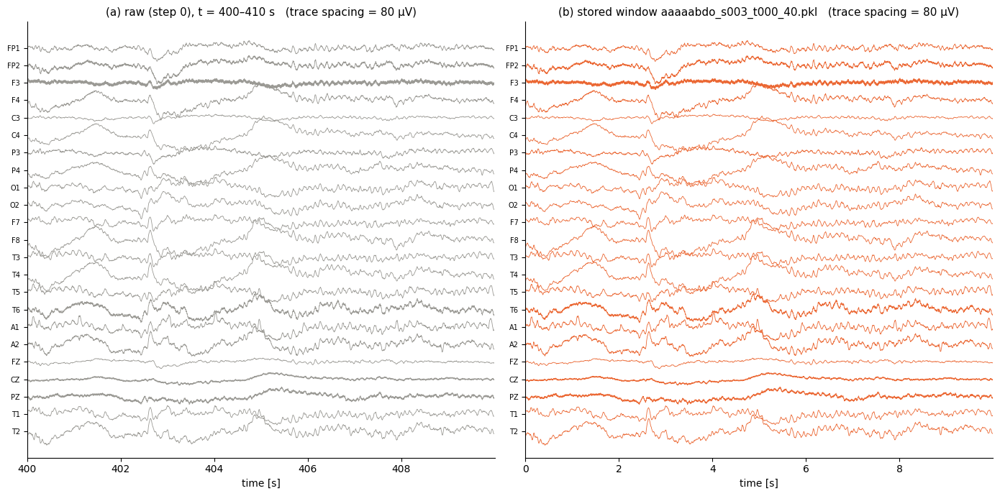

#### Figure 10.5. Abnormal recording aaaaabsk_s007_t000

142 windows; typical window k* = 91 (Eq. (10.1)): (a) raw, (b) stored.

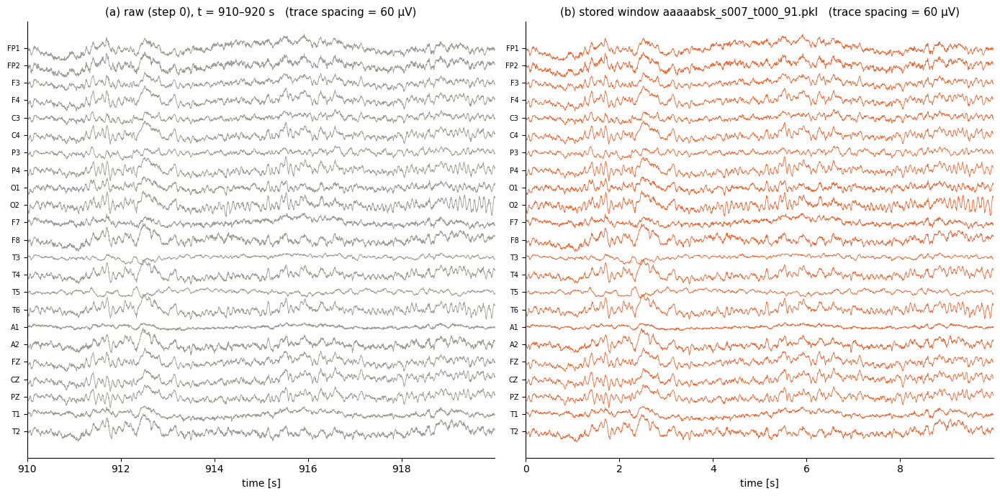

#### Figure 10.6. Abnormal recording aaaaabuv_s002_t000

138 windows; typical window k* = 73 (Eq. (10.1)): (a) raw, (b) stored.

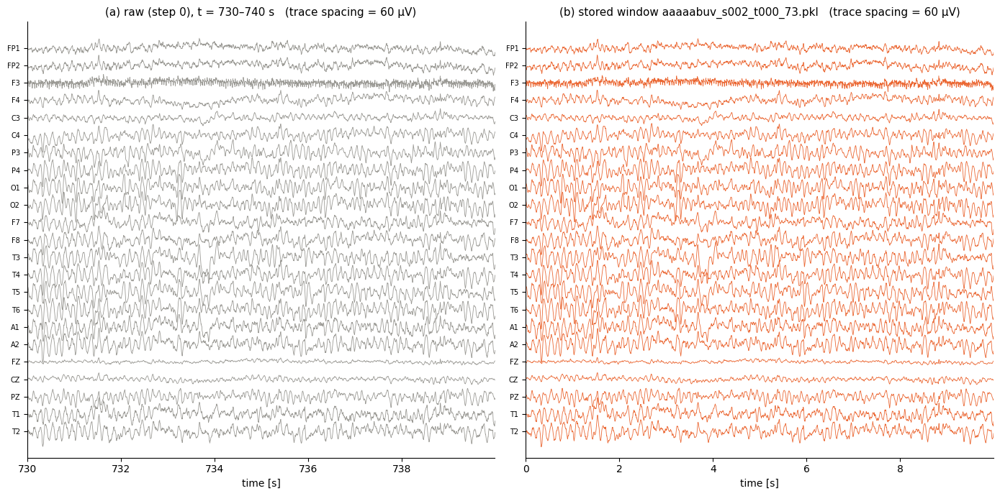

In [34]:
N_GALLERY = 3
gallery = [(0, s) for s in eval_normal[:N_GALLERY]] + [(1, s) for s in eval_abnormal[:N_GALLERY]]

def typical_window(windows):
    p99 = np.percentile(np.abs(windows), 99, axis=(1, 2))     # Eq. (10.1)
    return int(np.argsort(p99)[len(p99) // 2])

fig_no = 1
for label, stem in gallery:
    try:
        stages, windows = run_pipeline(edf_path("eval", label, stem), keep_stages=False)
    except RuntimeError as e:
        print("skipped:", e)
        continue
    k = typical_window(windows)
    Xr, chr_, sfr = stages["0 raw"]
    eeg = [chr_.index(c) for c in chOrder_standard]
    figure_heading(f"10.{fig_no}", f"{CLASS_NAME[label].capitalize()} recording {stem}",
                   note=f"{len(windows)} windows; typical window k* = {k} (Eq. (10.1)): (a) raw, (b) stored.",
                   level=4)
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    sp = plot_stacked(axes[0], Xr[eeg], chOrder_standard, sfr, k * 10, 10, color=C_BEFORE,
                      title=f"raw (step 0), t = {k * 10}–{k * 10 + 10} s")
    plot_stacked(axes[1], windows[k], chOrder_standard, TARGET_SFREQ, 0, 10, spacing=sp,
                 color=CLASS_COLOR[label], title=f"stored window {stem}_{k}.pkl")
    finish(fig, list(axes))
    fig_no += 1

### 10.2 Class-level comparison (all test recordings)

A single window says little; Figure 10.7 averages over all test recordings, re-using the per-recording
processed spectra $S_r(f)$ of section 2.1 (stored windows, i.e. exactly what the model sees). The
**relative band power** of recording $r$ in band $b$ is

$$
\begin{aligned}
P^{\text{rel}}_{r,b} &= \frac{\int_{f \in b} S_r(f)\,df}{\int_{0.5}^{45} S_r(f)\,df},\\
b &\in \{\delta: 0.5\text{–}4,\ \theta: 4\text{–}8,\ \alpha: 8\text{–}13,\ \beta: 13\text{–}30,\ \gamma: 30\text{–}45\}\ \text{Hz}
\end{aligned}
\tag{10.2}
$$

(unitless; the denominator stops at 45 Hz so that the untouched 60 Hz mains line, Table 2.2, does not
distort the ratios; integrals by the trapezoidal rule on the 0.25 Hz grid).

#### Figure 10.7. Normal vs abnormal: spectra of all test recordings

(a) Median processed PSD per class (shaded: inter-quartile range across recordings), all
test recordings; (b) relative band power, Eq. (10.2), per recording and class (boxes = quartiles, whiskers =
5th–95th percentile).

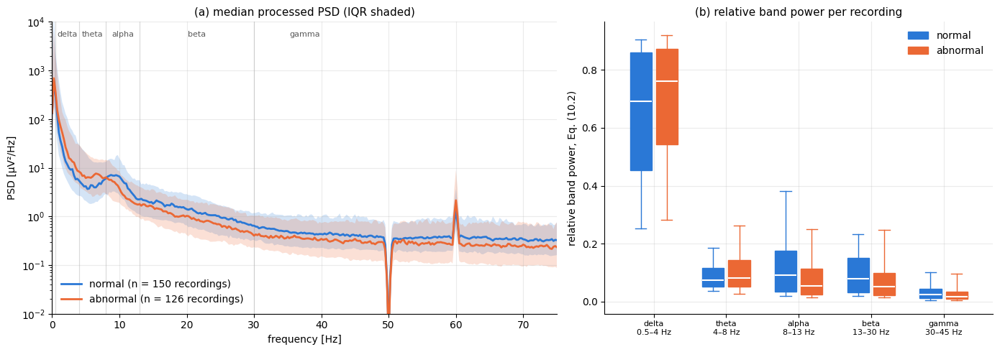

In [35]:
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
okp = ~np.isnan(GA["proc"][:, 10])
Sp, yp = GA["proc"][okp], GA["y"][okp]


def band_rel(S):
    tot = np.trapz(S[(F_PROC >= 0.5) & (F_PROC <= 45)], F_PROC[(F_PROC >= 0.5) & (F_PROC <= 45)])
    return [np.trapz(S[(F_PROC >= lo) & (F_PROC <= hi)], F_PROC[(F_PROC >= lo) & (F_PROC <= hi)]) / tot
            for lo, hi in BANDS.values()]


band = np.array([band_rel(s) for s in Sp])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for label in (0, 1):
    q25, q50, q75 = np.percentile(Sp[yp == label], [25, 50, 75], axis=0)
    ax.fill_between(F_PROC, q25, q75, color=CLASS_COLOR[label], alpha=0.2, lw=0)
    ax.semilogy(F_PROC, q50, color=CLASS_COLOR[label], lw=2,
                label=f"{CLASS_NAME[label]} (n = {np.sum(yp == label)} recordings)")
for name, (lo, hi) in BANDS.items():
    ax.axvline(lo, color="0.85", lw=0.8, zorder=0)
    ax.text((lo + hi) / 2, 0.97, name, ha="center", va="top", fontsize=8, color="0.35",
            transform=ax.get_xaxis_transform())
ax.set_xlim(0, 75)
ax.set_ylim(1e-2, 1e4)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("PSD [µV²/Hz]")
ax.set_title("median processed PSD (IQR shaded)")
ax.legend(loc="lower left")
ax = axes[1]
pos = np.arange(len(BANDS))
for j, label in enumerate((0, 1)):
    bp = ax.boxplot(band[yp == label], positions=pos + (j - 0.5) * 0.36, widths=0.3, whis=(5, 95),
                    patch_artist=True, showfliers=False, medianprops=dict(color="white", lw=1.5))
    for b in bp["boxes"]:
        b.set(facecolor=CLASS_COLOR[label], edgecolor=CLASS_COLOR[label])
    for part in ("whiskers", "caps"):
        for l_ in bp[part]:
            l_.set(color=CLASS_COLOR[label])
ax.set_xticks(pos, [f"{n}\n{lo}–{hi} Hz" for n, (lo, hi) in BANDS.items()], fontsize=8)
ax.set_ylabel("relative band power, Eq. (10.2)")
ax.set_title("relative band power per recording")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[l]) for l in (0, 1)], [CLASS_NAME[l] for l in (0, 1)])
finish(fig, list(axes))

#### Table 10.1. Relative band power and amplitude per class

Median over test recordings of Eq. (10.2) per band, and of $q_{99}(\lvert X\rvert)$ (µV, the 99th percentile of the
absolute amplitude over the sampled stored windows of a recording, as in Eq. (10.1)).

In [36]:
tab = pd.DataFrame({CLASS_NAME[l]: list(np.median(band[yp == l], axis=0)) + [np.nanmedian(GA["p99"][okp][yp == l])]
                    for l in (0, 1)},
                   index=[f"P_rel {n}" for n in BANDS] + ["q99 |X| [µV]"])
tab["n"] = f"{np.sum(yp == 0)} / {np.sum(yp == 1)}"
display(numbered_table(tab, "10.1", "band power per class", precision=3))

,normal,abnormal,n
P_rel delta,0.692,0.762,150 / 126
P_rel theta,0.072,0.080,150 / 126
P_rel alpha,0.090,0.054,150 / 126
P_rel beta,0.078,0.052,150 / 126
P_rel gamma,0.023,0.017,150 / 126
q99 |X| [µV],94.212,86.973,150 / 126


**Reading Figure 10.7 and Table 10.1.** The normal median spectrum has a distinct **alpha peak around 10 Hz**,
which is flattened in the abnormal group, and abnormal recordings carry a larger **relative delta and
theta** share (slowing). The groups overlap heavily, though — the IQR bands and boxes intersect in every
band — which is why the task needs a learned model rather than a single spectral threshold. Both groups
show the notch dip at 50 Hz and the untouched mains peak at 60 Hz.

### 10.3 Spectrogram of whole recordings

The time-frequency picture over the full recording (after preprocessing, O1 — an occipital channel
where the alpha rhythm is strongest), in dB:

$$
S(\tau, f) = 10\log_{10}\frac{2\,\big\lvert \sum_{n=0}^{L-1} w[n]\,x[n + \tau L/2]\, e^{-j2\pi f n/f_s}\big\rvert^2}{f_s \sum_n w[n]^2}
\tag{10.3}
$$

with a 4 s Tukey window $w$ (`scipy.signal.spectrogram` default), $L = 4 f_s$, 50 % overlap; $\tau$ indexes the
segment. Horizontal bands = sustained rhythms (alpha ~10 Hz, the faint 60 Hz mains line, the dark 50 Hz
notch), vertical stripes = broadband artefacts (movement, electrode pops) that are kept in the training data.

#### Figure 10.8. Spectrogram of a whole recording

Spectrogram, Eq. (10.3), of O1 after preprocessing (step 4) over the whole recording for
(a) the normal and (b) the abnormal example (dB re 1 µV²/Hz).

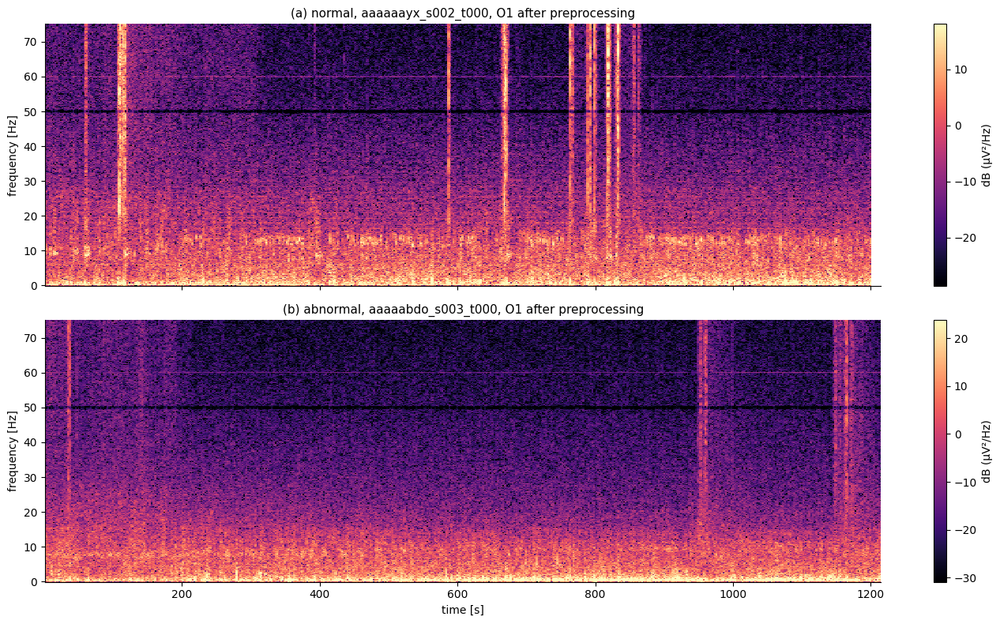

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["4 resampled"]
    i = ch.index("EEG O1-REF")
    f, t, S = ss.spectrogram(X[i], fs=sf, nperseg=int(4 * sf), noverlap=int(2 * sf))
    m = f <= 75
    SdB = 10 * np.log10(S[m] + 1e-6)
    pc = ax.pcolormesh(t, f[m], SdB, shading="auto", cmap="magma",
                       vmin=np.percentile(SdB, 5), vmax=np.percentile(SdB, 99.5))
    ax.set_ylabel("frequency [Hz]")
    ax.set_title(f"{CLASS_NAME[label]}, {stem}, O1 after preprocessing")
    ax.grid(False)
    fig.colorbar(pc, ax=ax, label="dB (µV²/Hz)")
axes[-1].set_xlabel("time [s]")
finish(fig, list(axes))

## 11. Summary of formulas & caveats

### Table 11.1. All steps with their formulas

| Step | Operation | Formula | Parameters (MNE defaults in *italics*) |
|------|-----------|---------|----------------------------------------|
| 0 | EDF → µV | Eq. (2.1) | $f_s = 250$ Hz |
| 1 | channel selection | Eq. (3.1) | `drop_channels`, `chOrder_standard` |
| 2 | band-pass | Eqs. (4.1)–(4.5) | 0.1–75 Hz, *firwin, 8251 taps, Δf = 0.1 / 18.75 Hz* (Table 4.1) |
| 3 | notch | Eq. (5.1) | 50 Hz, *width 0.25 Hz, transition 1 Hz* |
| 4 | resample | Eqs. (6.1)–(6.2) | 250 → 200 Hz, *FFT, boxcar* |
| 5 | windowing | Eq. (7.1) | 10 s, no overlap, tail dropped |
| 6 | model input | Eqs. (8.1)–(8.2) | `[23, 10, 200]`, ÷100 |
| 7 | *(LaBraM++)* | Eqs. (9.1)–(9.2) | opt-in |

Figure 11.1 (end of this section) follows one channel of the same 10 s window through every step of Table 11.1.

**Caveats worth knowing**

1. **60 Hz mains noise is not removed** (section 5, Table 2.2): the notch is at 50 Hz but TUH is US data.
2. **No artefact handling**: no rejection of bad windows/channels, no re-referencing (unless
   LaBraM++), only a fixed ÷100 scale. High-amplitude artefact windows go into training as-is (Figure 4.5).
3. **Weak labels**: each 10 s window inherits the recording-level label (Eq. (7.1)); an abnormal
   recording can contain many normal-looking windows. Recording-level evaluation (aggregating
   window predictions, see `docs/finetune_evaluation.md`) is closer to the clinical question.
4. **Split reproducibility / leakage**: `make_TUAB.py` calls `np.random.shuffle` **without a
   seed**, and Eq. (1.1) splits normal and abnormal subjects **independently**, so a subject who has both
   normal and abnormal recordings can land in train for one and val for the other (Table 11.2).
   The official `eval/` test set is fixed and unaffected. `docs/age_regression.md` describes a
   seeded, subject-disjoint split.
5. **Skipped recordings**: files whose channel set does not reduce to exactly the 23 channels are
   dropped (logged to `tuab-process-error-files.txt`) — counted in Table 11.2.

### Table 11.2. Split and coverage checks of the stored `processed/` folder

Recording and subject counts per stored split, EDF recordings missing from `processed/` (skipped by
Eq. (3.1)), and subject overlaps between splits.

In [38]:
if PROCESSED.exists():
    proc_stems, proc_subj = {}, {}
    for split in ("train", "val", "test"):
        proc_stems[split] = {fn[:-4].rsplit("_", 1)[0] for fn in os.listdir(PROCESSED / split)}
        proc_subj[split] = {s.split("_")[0] for s in proc_stems[split]}
    edf_stems = {p.stem for sp in ("train", "eval") for c in ("normal", "abnormal")
                 for p in (TUAB_ROOT / sp / c / MONTAGE).glob("*.edf")}
    all_proc = set().union(*proc_stems.values())
    both = ({p.stem.split('_')[0] for p in (TUAB_ROOT / 'train/normal' / MONTAGE).glob('*.edf')}
            & {p.stem.split('_')[0] for p in (TUAB_ROOT / 'train/abnormal' / MONTAGE).glob('*.edf')})
    rows = [(f"processed/{s} recordings / subjects", f"{len(proc_stems[s])} / {len(proc_subj[s])}") for s in proc_stems]
    rows += [
        ("EDF recordings / processed recordings", f"{len(edf_stems)} / {len(all_proc)}"),
        ("skipped by make_TUAB.py", ", ".join(sorted(edf_stems - all_proc)) or "none"),
        ("subjects with normal AND abnormal recordings in train/", str(len(both))),
        ("subjects in both processed/train and processed/val (leakage)", str(len(proc_subj["train"] & proc_subj["val"]))),
        ("subjects shared between train/val and test", str(len((proc_subj["train"] | proc_subj["val"]) & proc_subj["test"]))),
    ]
    display(numbered_table(pd.DataFrame(rows, columns=["check", "value"]).set_index("check"), "11.2", "split checks"))
else:
    print("processed/ folder not found — skipping")

,value
check,
processed/train recordings / subjects,2142 / 1668
processed/val recordings / subjects,572 / 423
processed/test recordings / subjects,276 / 253
EDF recordings / processed recordings,2993 / 2990
skipped by make_TUAB.py,"aaaaajsl_s010_t000, aaaaakfo_s004_t000, aaaaakfo_s005_t000"
subjects with normal AND abnormal recordings in train/,54
subjects in both processed/train and processed/val (leakage),16
subjects shared between train/val and test,0


### Figure 11.1. The same 10 s of Cz after every processing step

The **same 10 s window** (`SHOW_T0` … `SHOW_T0 + 10` s, = stored window $k$ = `SHOW_T0`/10) of Cz
after every step, for (a) the normal and (b) the abnormal example: step 0/1 raw (250 Hz; channel
selection does not change Cz), step 2 band-pass, step 3 notch, step 4 resampled (200 Hz), step 5 stored
pickle, step 6 model input (Eq. (8.1), shown ×100). Traces offset vertically, all in µV; scale bar 50 µV.

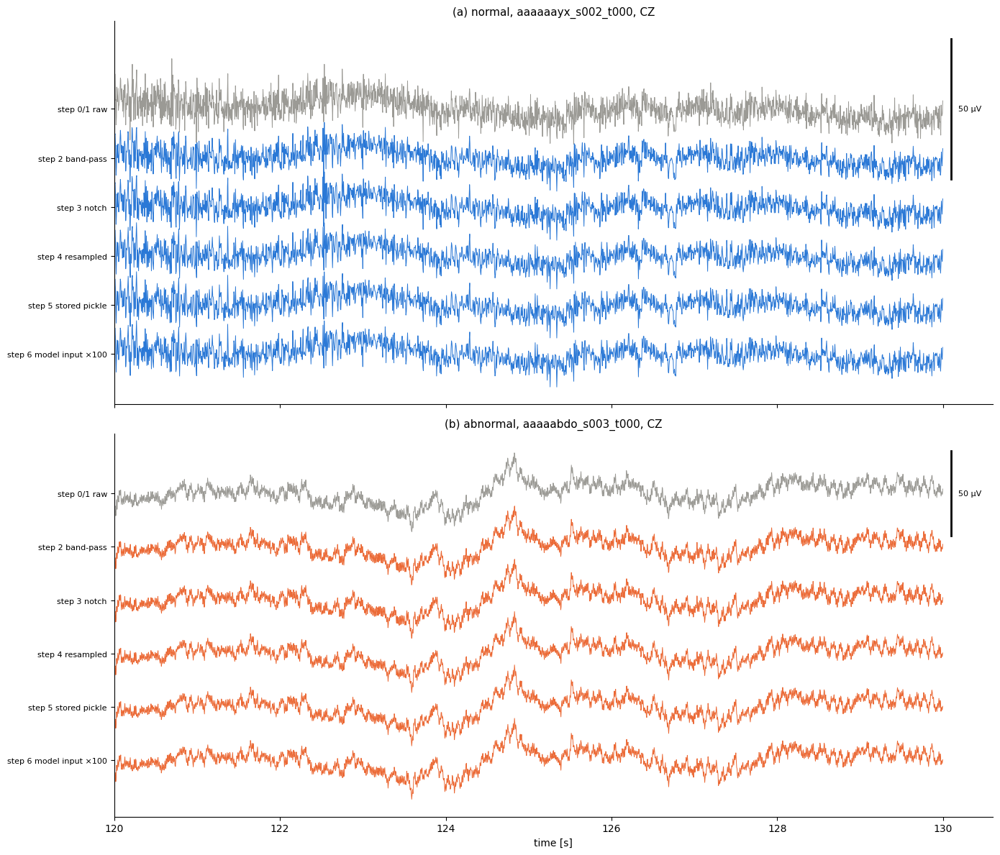

In [39]:
def stage_traces(label):
    st, windows = pipe[label]
    k = int(SHOW_T0 // 10)
    split = find_processed(examples[label])
    stored = None
    if split is not None:
        with open(PROCESSED / split / f"{examples[label]}_{k}.pkl", "rb") as fh:
            stored = pickle.load(fh)["X"]
    out = []
    for name, key in (("step 0/1 raw", "1 channels"), ("step 2 band-pass", "2 band-pass"),
                      ("step 3 notch", "3 notch"), ("step 4 resampled", "4 resampled")):
        X, ch, sf = st[key]
        i0 = int(SHOW_T0 * sf)
        out.append((name, X[ch.index(CH), i0:i0 + int(SHOW_DUR * sf)], sf))
    ci = chOrder_standard.index(CH)
    if stored is not None:
        out.append(("step 5 stored pickle", stored[ci], TARGET_SFREQ))
    out.append(("step 6 model input ×100", (windows[k][ci] / 100) * 100, TARGET_SFREQ))
    return out


fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    tr = stage_traces(label)
    off = 5 * np.std(tr[-1][1])
    for j, (name, y, sf) in enumerate(tr):
        t = SHOW_T0 + np.arange(len(y)) / sf
        ax.plot(t, y - np.mean(y) - j * off, lw=0.7,
                color=C_BEFORE if j == 0 else CLASS_COLOR[label])
    ax.set_yticks([-j * off for j in range(len(tr))], [n for n, _, _ in tr], fontsize=8)
    ax.plot([SHOW_T0 + SHOW_DUR + 0.1] * 2, [-25, 25], color="k", lw=2, clip_on=False)
    ax.text(SHOW_T0 + SHOW_DUR + 0.18, 0, "50 µV", va="center", fontsize=8)
    ax.set_xlim(SHOW_T0, SHOW_T0 + SHOW_DUR + 0.6)
    ax.grid(False)
    ax.set_title(f"{CLASS_NAME[label]}, {stem}, {short(CH)}")
axes[-1].set_xlabel("time [s]")
finish(fig, list(axes))

## 12. How do other state-of-the-art models prepare EEG?

LaBraM's recipe is one choice among many. Tables 12.1 and 12.2 compare the published
preprocessing of **EEG foundation models** and of **EEG age-prediction ("brain age") models**, the
downstream task this repo also supports (`data.dataset=TUAB_AGE`, `docs/age_regression.md`). The values
were taken from each paper's methods/appendix and, where marked *(code)*, from the official preprocessing
scripts. "n/s" = not stated in the paper.

### Table 12.1. Preprocessing of EEG foundation models

| Model (venue) | Pre-training data | Channels / reference | Band-pass · notch | Rate | Amplitude scaling | Artefact handling | Window · token | Input representation |
|---|---|---|---|---|---|---|---|---|
| **BENDR** (Kostas et al., *Front. Hum. Neurosci.* 2021) | TUEG v1.1–1.2, ~1.5 TB, >10k people | 19 ch (10-20, DN3 mapping), missing → 0, **+1 relative-amplitude channel**; no re-ref | none (only Nyquist-safe files kept) | 256 Hz | each sequence min–max scaled to **[−1, 1]** | none | 60 s · conv tokens ≈ 0.375 s (96× down-sampling) | raw time series |
| **BIOT** (Yang et al., *NeurIPS* 2023) | SHHS + PREST (private), ~10 M samples; some variants on TUAB/IIIC/CHB-MIT | **16 bipolar TCP** (double banana) computed from `-REF` chans *(code)*; missing channels → dropped tokens | **none** *(code)* | 200 Hz | per channel ÷ **95th percentile of \|x\|** per sample *(code)*, Eq. (12.1) | none | TUAB 10 s · 1 s tokens, 0.5 s overlap | **STFT** energy per token (n_fft = 200, hop 100) |
| **LaBraM** (Jiang et al., *ICLR* 2024) — *this repo* | ~2,535 h, ~20 datasets (TUSZ, TUEP, SEED, …) | up to 128 ch, learned 10-20 spatial embedding; TUAB **23 referential** `-REF` chans; no re-ref | **0.1–75 Hz · 50 Hz** | 200 Hz | µV **÷ 100** (0.1 mV units), Eq. (8.1) | none | TUAB 10 s · 1 s patches (200 samples), ≤ 256 patches | raw patches (VQ tokenizer target: Fourier amplitude & phase) |
| **EEGPT** (Wang et al., *NeurIPS* 2024) | PhysioMI, HGD, TSU, SEED, M3CV | 58 ch, **average reference** in pre-training; downstream 1×1-conv "adaptive spatial filter" | n/s for pre-training (0–38 Hz for MI downstream) | 256 Hz | **mV** (V × 1000) | n/s | 4 s · 250 ms patches (64 samples) | raw patches |
| **CBraMod** (Wang et al., *ICLR* 2025) | TUEG, >9,000 h after cleaning | 19 ch referential (`-REF`/`-LE`); conv positional encoding; TUAB **16 bipolar TCP** *(code)* | **0.3–75 Hz · 60 Hz** | 200 Hz | µV **÷ 100** | drop recordings ≤ 5 min, **drop first & last minute**, **reject 30 s samples with \|x\| > 100 µV** | 30 s (TUAB 10 s) · 1 s patches | raw patch (time-conv) + FFT branch |
| **NeuroLM** (Jiang et al., *ICLR* 2025) | ~25,000 h (~24,000 h TUEG) | variable, LaBraM-style spatial embedding; TUAB 23 ch | 0.1–75 Hz · **50 or 60 Hz by region** | 200 Hz | µV **÷ 100** | n/s | TUAB 10 s · 1 s patches, ≤ 1,024 patches | VQ tokens → GPT-2 (multi-task LLM) |
| **Neuro-GPT** (Cui et al., *ISBI* 2024) | TUH EEG, 20k recordings, 5,656 h | 22 ch, bad chans interpolated, **average reference** | **0.5–100 Hz · 60 Hz** | 250 Hz | DC removal, detrend, **z-score per recording** | bad-channel interpolation | 32 × 2 s chunks (10 % overlap) | raw chunks → conv + transformer → GPT-2 |
| **FEMBA** (Tegon et al., arXiv 2025) | TUEG ~21,000 h (TUAB/TUAR/TUSL removed) | n/s | n/s | n/s | per channel **IQR (quartile) scaling** | n/s | 2-D patches (4 ch × 32 samples) | raw patches → bidirectional Mamba |
| **REVE** (El Ouahidi et al., *NeurIPS* 2025) | 61,415 h, 92 datasets, ~25k subjects | any montage, **4-D (xyz + time) positional encoding** | **0.5–99.5 Hz** · n/s | 200 Hz | **z-score** (session stats), **clip ±15 SD** | none (no rejection) | ~10 s · 1 s patches (0.1 s overlap) | raw patches |

Footnotes: BENDR/BIOT/EEGPT do not report pre-training hours. EEGPT's paper text says 256 Hz for TUAB, but its
released TUAB script is LaBraM's pipeline (0.1–75 Hz, 50 Hz notch, 200 Hz, ÷100). FEMBA's filter/rate/montage are
not given in the paper.

### Table 12.2. Preprocessing of EEG age-prediction (brain-age) models

| Work | Data (N, age) | Channels / reference | Filtering | Rate | Artefact handling | Segments | Scaling | Features → model | Recording-level age | MAE |
|---|---|---|---|---|---|---|---|---|---|---|
| **Engemann et al.**, *NeuroImage* 2022 — M/EEG brain-age benchmark *(values from code)* | TUAB **normal** recordings, 1,385 subj., 0–95 y (+ Cam-CAN, LEMON, CHBP) | 21 ch (10-20 + A1/A2), **average reference** | **0.1–49 Hz**, no notch | 200 Hz | **autoreject** on epochs | 10 s | µV ÷ 9.7 (dataset SD) for deep nets, Eq. (12.2) | filter-bank **Riemann** covariances (7 bands) + ridge; hand-crafted + RF; ShallowNet / Deep4 | mean of window predictions | TUAB: Deep4 7.75, Shallow 7.80, Riemann 8.25 y |
| **Gemein et al.**, *Imaging Neurosci.* 2024 — "Brain age revisited" | TUAB, 2,647 rec. / 2,159 subj. (train on non-pathological) | 21 ch, **common average** | n/s | **100 Hz** | **drop first minute**, **clip ±800 µV** | braindecode cropped decoding (stride 1) | channel z-score (train stats), Eq. (12.3); target min-max [0, 1] | BD-TCN, L1 loss | crop mean (likely; not explicit) | 6.6 y (R² 0.73) |
| *Gemein et al.*, *NeuroImage* 2020 — TUAB **pathology** (the reference braindecode TUAB recipe) | TUAB 2,993 rec. | 21 ch | none | 100 Hz | drop first 60 s, ≤ 20 min, clip ±800 µV | ~6 s receptive-field crops | — | Deep4 / Shallow / TCN / EEGNet; RF / SVM / Riemann | crop aggregation | (classification, 86 % acc.) |
| **Sun et al.**, *Neurobiol. Aging* 2019 — sleep EEG | MGH PSG, 2,532 (18–80 y) | 6 ch (F3/F4/C3/C4/O1/O2 – contralateral mastoid) | **0.5–20 Hz · 60 Hz** | 200 Hz | reject 30 s epochs > 500 µV, flat > 2 s, ECG-contaminated | 30 s sleep epochs | per channel median / IQR over the night | 102 features × 5 sleep stages → regularised linear model | features averaged per stage | 7.8 y |
| **Brink-Kjaer et al.**, *npj Digit. Med.* 2022 — deep PSG | 13,332 PSGs, 7 cohorts, 6–90 y | C3-M2, C4-M1 (+ EOG/EMG/ECG variants) | 0.3–45 Hz elliptic IIR, zero phase | 128 Hz | n/s | 5 min epochs | 5th/95th percentile → [−1, 1] | CNN + Bi-LSTM + attention, Huber loss | 2nd-stage Bi-LSTM + attention over the night | 5.8 y |
| **Khayretdinova et al.**, *Front. Aging Neurosci.* 2022 | TD-BRAIN, 1,335 sessions, 5–88 y | 26 ch (10-10), averaged mastoids | **0.5–100 Hz · 50/60 Hz** | 500 Hz | EOG regression + automatic EMG / jump / kurtosis / blink detection, flagged segments dropped | 5 s, 1 s step | n/s | deep CNN with channel-permutation stacking, L1 loss | mean of clean-segment predictions | 5.96 y |
| **Sabbagh et al.**, *BJA Open* 2023 — anaesthesia EEG | 323 patients ≥ 18 y | 4 frontal (Fp1/Fp2/F7/F8 – Cz) | n/s | 63 Hz | burst-suppression / artefacts removed by vendor export; keep stable-anaesthesia segment | 60 s, 10 s shift | — | PSD + 5-band covariances (coffeine) → ridge | averaged over epochs | ~8.2 y |
| **Banville et al.**, *Imaging Neurosci.* 2024 — Muse mobile EEG | 4,191 meditation + 1,020 sleep rec., 18–81 y | 4 ch (TP9, Fp1, Fp2, TP10), Fpz ref | 0.1–49 Hz FIR + notches 16 … 60 Hz | 128 Hz | crop first minute; reject windows with peak-to-peak > 250 µV | 10 s / 30 s | — | filter-bank covariances → ridge | averaged features | 9.3 y / 7.6 y |
| **This repo**, `TUAB_AGE` (`docs/age_regression.md`) | TUAB, age from EDF header, subject-disjoint split | 23 ch referential (LaBraM) | 0.1–75 Hz · 50 Hz | 200 Hz | none | 10 s | µV ÷ 100; **target** z-scored with train stats | fine-tuned LaBraM, Huber loss | mean / median / max of windows | — (literature range 7–8 y) |

### 12.3 What differs, and why it matters

* **Montage.** On TUAB, BIOT and CBraMod use the **16-channel bipolar TCP** montage; LaBraM, NeuroLM and
  EEGPT use **23 referential** channels; the brain-age works use **21 channels re-referenced to the
  common average**. Bipolar and average-reference montages remove the signal shared by the electrodes in
  each derivation, e.g. the activity of the shared reference electrode; with referential channels
  (LaBraM) that shared component stays in every channel.
* **Line noise.** TUH is US data (60 Hz). LaBraM/EEGPT notch at 50 Hz (section 5), CBraMod and
  Neuro-GPT at 60 Hz, NeuroLM by region; the TUAB age benchmarks avoid the issue with a ≤ 49 Hz low-pass or a
  100 Hz rate (Nyquist 50 Hz).
* **Amplitude scaling** falls into three families: a **fixed physical unit** (÷100 µV: LaBraM, CBraMod,
  NeuroLM; mV: EEGPT; ÷9.7 µV: Engemann) keeps absolute amplitude, which carries information
  (amplitude falls with age); **per-sample/per-channel normalisation** (BIOT 95th percentile, FEMBA
  IQR, BENDR min-max) discards it; **z-scoring with dataset/session statistics** (Gemein, REVE,
  Neuro-GPT) is in between.
* **Artefacts.** The foundation models mostly keep everything (CBraMod is the exception, rejecting
  windows with |x| > 100 µV and the first/last minute), whereas the brain-age literature almost always
  removes or clips artefacts (autoreject, ±800 µV clip, peak-to-peak thresholds, first-minute crop).
* **Recording-level aggregation.** Every brain-age work predicts **one age per recording**, typically by
  averaging window predictions or features, which is why this repo evaluates age per recording.

### 12.4 Five recipes applied to the same excerpt

The next cells re-implement five of these recipes (simplified, see the code comments) on the step-1 signal
$x_c$ (µV) of the abnormal example. Besides the filters and rates of Table 12.1/12.2, they scale amplitudes as

$$
\hat x_c = \frac{x_c}{q_{95}\big(\lvert x_c\rvert\big) + 10^{-8}}\quad\text{(BIOT, per channel and 10 s sample)}
\tag{12.1}
$$

$$
\hat x_c = \frac{1}{9.7}\Big(x_c - \frac{1}{C}\sum_{c'} x_{c'}\Big)\quad\text{(Engemann 2022: average reference, ÷ 9.7 µV)}
\tag{12.2}
$$

$$
\begin{aligned}
\hat x_c &= \frac{u_c - \operatorname{mean}(u_c)}{\operatorname{std}(u_c)}\quad\text{(Gemein 2024)},\\
u_c &= \operatorname{clip}_{\pm 800}(x_c) - \frac{1}{C}\sum_{c'} \operatorname{clip}_{\pm 800}(x_{c'})
\end{aligned}
\tag{12.3}
$$

where $q_{95}$ is the 95th percentile over the samples of the window, $C = 21$ channels, and mean/std are over
time (first minute excluded; this recording's statistics stand in for the training-set statistics). LaBraM
and CBraMod use the ÷100 of Eq. (8.1). Figure 12.1 shows the same 10 s under each recipe.

#### Figure 12.1. The same abnormal excerpt under five published recipes

The abnormal excerpt (`SHOW_T0` … `SHOW_T0 + 10` s) after (a) LaBraM / NeuroLM, (b) BIOT,
(c) CBraMod, (d) Engemann 2022 and (e) Gemein 2024 preprocessing; each panel in that recipe's model units
(spacing in the title), bipolar recipes show the 16 TCP derivations.

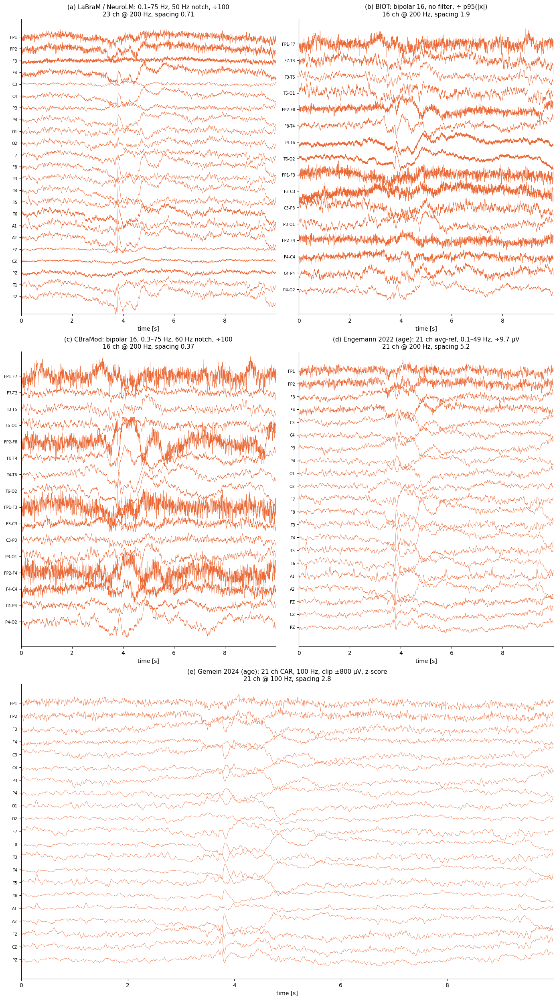

In [40]:
# Simplified re-implementations of published recipes, applied to step-1 data
# (23 referential channels, 250 Hz, µV, unfiltered). Simplifications:
#  * Engemann 2022: autoreject is skipped.
#  * Gemein 2024: z-score uses this recording's statistics instead of the training-set statistics.
#  * BIOT / CBraMod: TUAB bipolar TCP montage computed from the referential channels, as their scripts do.
TCP_PAIRS = [("FP1", "F7"), ("F7", "T3"), ("T3", "T5"), ("T5", "O1"),
             ("FP2", "F8"), ("F8", "T4"), ("T4", "T6"), ("T6", "O2"),
             ("FP1", "F3"), ("F3", "C3"), ("C3", "P3"), ("P3", "O1"),
             ("FP2", "F4"), ("F4", "C4"), ("C4", "P4"), ("P4", "O2")]
CH21 = [c for c in chOrder_standard if short(c) not in ("T1", "T2")]


def bipolar(X, ch):
    idx = {short(c): i for i, c in enumerate(ch)}
    return np.stack([X[idx[a]] - X[idx[b]] for a, b in TCP_PAIRS]), [f"{a}-{b}" for a, b in TCP_PAIRS]


def recipes(X1, ch, sf):
    # X1: [23, N] µV at sf (step-1 output). Returns name -> (X, channel labels, rate, unit).
    out = {}
    x = mne.filter.filter_data(X1, sf, 0.1, 75.0)                     # LaBraM: Eqs. (4.5), (5.1), (6.2), (8.1)
    x = mne.filter.notch_filter(x, sf, 50.0)
    out["LaBraM / NeuroLM\n0.1–75 Hz, 50 Hz notch, ÷100"] = (
        mne.filter.resample(x, TARGET_SFREQ / sf) / 100, ch, 200, "×100 µV")
    xb, chb = bipolar(X1, ch)                                          # BIOT: Eq. (12.1), per window below
    out["BIOT\nbipolar 16, no filter, ÷ p95(|x|)"] = (mne.filter.resample(xb, TARGET_SFREQ / sf), chb, 200, "p95")
    x = mne.filter.resample(xb, TARGET_SFREQ / sf)                     # CBraMod
    x = mne.filter.filter_data(x, 200., 0.3, 75.0)
    x = mne.filter.notch_filter(x, 200., 60.0)
    out["CBraMod\nbipolar 16, 0.3–75 Hz, 60 Hz notch, ÷100"] = (x / 100, chb, 200, "×100 µV")
    i21 = [ch.index(c) for c in CH21]                                  # Engemann: Eq. (12.2)
    x = mne.filter.filter_data(X1[i21], sf, 0.1, 49.0)
    x = mne.filter.resample(x, TARGET_SFREQ / sf)
    x = x - x.mean(axis=0, keepdims=True)
    out["Engemann 2022 (age)\n21 ch avg-ref, 0.1–49 Hz, ÷9.7 µV"] = (x / 9.7, CH21, 200, "×9.7 µV")
    x = mne.filter.resample(X1[i21], 100.0 / sf)                       # Gemein: Eq. (12.3)
    x = np.clip(x, -800, 800)
    x = x - x.mean(axis=0, keepdims=True)
    x[:, :60 * 100] = np.nan                                           # first minute discarded
    mu, sd = np.nanmean(x, axis=1, keepdims=True), np.nanstd(x, axis=1, keepdims=True)
    out["Gemein 2024 (age)\n21 ch CAR, 100 Hz, clip ±800 µV, z-score"] = ((x - mu) / sd, CH21, 100, "σ")
    return out


X1, ch1, sf1 = pipe[1][0]["1 channels"]
alt = recipes(X1, ch1, sf1)

fig = plt.figure(figsize=(14, 25))
gs = fig.add_gridspec(3, 2)
rax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0]),
       fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[2, :])]
for ax, (name, (X, chs, sf, unit)) in zip(rax, alt.items()):
    i0, i1 = int(SHOW_T0 * sf), int((SHOW_T0 + SHOW_DUR) * sf)
    W = X[:, i0:i1]
    if unit == "p95":
        W = W / (np.quantile(np.abs(W), 0.95, axis=-1, keepdims=True) + 1e-8)   # Eq. (12.1)
    sp = 4.0 * np.median(np.std(W - W.mean(1, keepdims=True), axis=1))
    plot_stacked(ax, W, chs, sf, 0, SHOW_DUR, spacing=float(f"{sp:.2g}"), color=C_ABNORMAL, lw=0.5,
                 labels=[short(c) if c.startswith("EEG") else c for c in chs])
    ax.set_title(name.replace("\n", ": ") + f"\n{len(chs)} ch @ {sf} Hz, spacing {sp:.2g}", fontsize=10)
finish(fig, rax)

**Which frequencies does each recipe pass to the model?** Figure 12.2 shows the spectrum of the whole
recording under each recipe, normalised to its own total power so that the different units do not matter:

$$
\hat S(f) = \frac{S(f)}{\int_0^{f_s/2} S(f')\,df'}
\tag{12.4}
$$

where $S$ is Eq. (2.3) of the recipe's output (unit 1/Hz). On this recording only CBraMod's 60 Hz notch,
Engemann's 49 Hz low-pass and Gemein's 100 Hz rate keep the mains line out of the model input; the
re-montaging alone (bipolar in BIOT) does not remove it (Table 12.3).

#### Figure 12.2. Spectrum passed to the model under each recipe

Normalised spectrum, Eq. (12.4), of the abnormal example under each recipe of Figure 12.1
(dotted: 50 and 60 Hz).

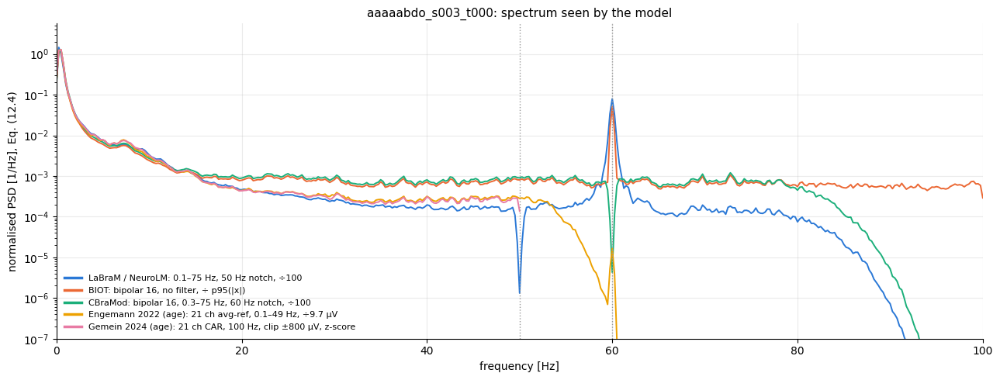

In [41]:
fig, ax = plt.subplots(figsize=(13, 5))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order
for col, (name, (X, chs, sf, unit)) in zip(palette, alt.items()):
    Xv = X[:, ~np.isnan(X).any(axis=0)]
    f, P = welch_psd(Xv, sf, seg_sec=4.0)
    Pm = P.mean(0)
    ax.semilogy(f, Pm / np.trapz(Pm, f), color=col, lw=1.4, label=name.replace("\n", ": "))
for f0 in (50, 60):
    ax.axvline(f0, color="0.6", ls=":", lw=1)
ax.set_xlim(0, 100)
ax.set_ylim(1e-7, None)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("normalised PSD [1/Hz], Eq. (12.4)")
ax.set_title(f"{EXAMPLE_ABNORMAL}: spectrum seen by the model")
thick_legend(ax, fontsize=8, loc="lower left")
finish(fig)

#### Table 12.3. Mains-line power reaching the model under each recipe

$\rho(60\text{ Hz})$ of Eq. (2.6) in dB for the abnormal example (8 s Welch segments); "none" when the
recipe's Nyquist frequency is below 60 Hz.

In [42]:
rows = []
for name, (X, chs, sf, unit) in alt.items():
    Xv = X[:, ~np.isnan(X).any(axis=0)]
    if sf / 2 <= 60.5:
        val = f"none (Nyquist {sf // 2} Hz)"
    else:
        f, P = welch_psd(Xv, sf, seg_sec=8.0)
        val = f"{line_power_db(f, P, 60):.1f}"
    rows.append({"recipe": name.replace("\n", ": "), "ρ(60 Hz) [dB], Eq. (2.6)": val})
display(numbered_table(pd.DataFrame(rows).set_index("recipe"), "12.3", "60 Hz power per recipe"))

,"ρ(60 Hz) [dB], Eq. (2.6)"
recipe,
"LaBraM / NeuroLM: 0.1–75 Hz, 50 Hz notch, ÷100",-6.2
"BIOT: bipolar 16, no filter, ÷ p95(|x|)",-9.4
"CBraMod: bipolar 16, 0.3–75 Hz, 60 Hz notch, ÷100",-31.5
"Engemann 2022 (age): 21 ch avg-ref, 0.1–49 Hz, ÷9.7 µV",-44.2
"Gemein 2024 (age): 21 ch CAR, 100 Hz, clip ±800 µV, z-score",none (Nyquist 50 Hz)


**References** (preprocessing values verified against the papers' methods sections and, where noted, official code)

* Kostas, Aroca-Ouellette & Rudzicz (2021). *BENDR.* Front. Hum. Neurosci. — [arXiv:2101.12037](https://arxiv.org/abs/2101.12037)
* Yang, Westover & Sun (2023). *BIOT.* NeurIPS — [arXiv:2305.10351](https://arxiv.org/abs/2305.10351), code: github.com/ycq091044/BIOT
* Jiang, Zhao & Lu (2024). *LaBraM.* ICLR — [arXiv:2405.18765](https://arxiv.org/abs/2405.18765), code: github.com/935963004/LaBraM
* Wang et al. (2024). *EEGPT.* NeurIPS — [paper](https://papers.neurips.cc/paper_files/paper/2024/file/4540d267eeec4e5dbd9dae9448f0b739-Paper-Conference.pdf), code: github.com/BINE022/EEGPT
* Wang et al. (2025). *CBraMod.* ICLR — [arXiv:2412.07236](https://arxiv.org/abs/2412.07236), code: github.com/wjq-learning/CBraMod
* Jiang et al. (2025). *NeuroLM.* ICLR — [arXiv:2409.00101](https://arxiv.org/abs/2409.00101)
* Cui et al. (2024). *Neuro-GPT.* ISBI — [arXiv:2311.03764](https://arxiv.org/abs/2311.03764)
* Tegon et al. (2025). *FEMBA.* — [arXiv:2502.06438](https://arxiv.org/abs/2502.06438)
* El Ouahidi et al. (2025). *REVE.* NeurIPS — [arXiv:2510.21585](https://arxiv.org/abs/2510.21585)
* Engemann et al. (2022). *A reusable benchmark of brain-age prediction from M/EEG resting-state signals.* NeuroImage 262:119521 — [doi](https://doi.org/10.1016/j.neuroimage.2022.119521), code: github.com/meeg-ml-benchmarks/brain-age-benchmark-paper
* Gemein et al. (2024). *Brain age revisited.* Imaging Neuroscience — [doi:10.1162/imag_a_00210](https://doi.org/10.1162/imag_a_00210)
* Gemein et al. (2020). *Machine-learning-based diagnostics of EEG pathology.* NeuroImage 220:117021 — [arXiv:2002.05115](https://arxiv.org/abs/2002.05115)
* Sun et al. (2019). *Brain age from the electroencephalogram of sleep.* Neurobiol. Aging 74:112–120 — [doi](https://doi.org/10.1016/j.neurobiolaging.2018.10.016)
* Brink-Kjaer et al. (2022). *Age estimation from sleep studies using deep learning.* npj Digit. Med. 5:103 — [doi](https://doi.org/10.1038/s41746-022-00630-9)
* Khayretdinova et al. (2022). *Predicting age from resting-state scalp EEG with deep CNNs on TD-BRAIN.* Front. Aging Neurosci. 14:1019869 — [doi](https://doi.org/10.3389/fnagi.2022.1019869)
* Sabbagh et al. (2023). *Repurposing EEG monitoring of general anaesthesia for brain-age prediction.* BJA Open — [doi](https://doi.org/10.1016/j.bjao.2023.100145)
* Banville et al. (2024). *Brain age from mobile (Muse) EEG.* Imaging Neuroscience — [doi](https://doi.org/10.1162/imag_a_00189)

**Where to go next**
* `dataset_maker/make_TUAB.py` — the offline script (run it once to create `processed/`).
* `labram/data/tuh_datasets.py` — `TUABLoader` / `prepare_TUAB_dataset` (reads the pickles).
* `labram/train/train_finetune.py` — ÷100 scaling and patching.
* `docs/labram_plus_plus.md` — CAR + z-score + sin/cos phase loss.
* `notebooks/finetune_evaluation.ipynb` — evaluating a fine-tuned model per window and per recording.

## 13. Export to PDF

The PDF next to this notebook ([`tuab_data_preparation.pdf`](tuab_data_preparation.pdf)) is rendered from the
**saved** notebook by `scripts/notebook_to_pdf.py`: nbconvert's `webpdf` exporter prints the HTML view with
headless Chromium, so MathJax typesets every `$$ … \tag{s.k} $$` formula with its number, Markdown and
pandas tables and figures keep their `Table s.k` / `Figure s.k` headings. Code cells are hidden
(`--no-input`); cells tagged `pdf-skip` (this section's code) are dropped.

```bash
pip install "nbconvert[webpdf]" && python -m playwright install chromium   # once
python scripts/notebook_to_pdf.py notebooks/tuab_data_preparation.ipynb --execute
```

Set `EXPORT_PDF = True` and run the cell below to export from here (save the notebook first: the
exporter reads the file on disk); the next cell shows the PDF inline.

In [43]:
EXPORT_PDF = False
NB_PATH = REPO_ROOT / "notebooks" / "tuab_data_preparation.ipynb"
PDF_PATH = NB_PATH.with_suffix(".pdf")
if EXPORT_PDF:
    import subprocess
    subprocess.run([sys.executable, str(REPO_ROOT / "scripts" / "notebook_to_pdf.py"), str(NB_PATH)], check=True)
print("PDF:", PDF_PATH, "(exists)" if PDF_PATH.exists() else "(not generated yet)")

PDF: /data/code/LaBraM/.claude/worktrees/bridge-cse_01GkNcrgGBSAwJPQMRAVe8ux/notebooks/tuab_data_preparation.pdf (exists)


In [44]:
from IPython.display import IFrame
IFrame(os.path.relpath(PDF_PATH, Path.cwd()), width="100%", height=800) if PDF_PATH.exists() else None